# Loss Functions for Marketers: How Models Decide What "Wrong" Means

**Companion notebook for the Marketing Data Science article**
by Joe Domaleski, [Country Fried Creative](https://countryfriedcreative.com) | [blog.marketingdatascience.ai](https://blog.marketingdatascience.ai)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/joedom99/loss-functions-for-marketers/blob/main/loss_functions_for_marketers.ipynb)

---

## What this notebook does

In my last article, [Objective Functions for Marketers](https://github.com/joedom99/objective-functions-for-marketers), a budget optimizer chose a marketing plan by maximizing profit, conversions, or a blend of the two. That was an objective for a **decision**. This notebook is about the objective a model uses to **learn**.

When a predictive model learns from data, it searches for the settings that make its mistakes as small as possible. The formula that scores those mistakes is the **loss function**. It's how a model decides what "wrong" means, and therefore what "right" means too. Most of the time it's a default nobody chose on purpose. But the loss decides what the forecast is aiming for, and the forecast feeds the business decision. Change the loss, and the same data produces a different forecast and a different decision.

This notebook covers two common families of loss functions:

- **Regression losses** score predictions of a number on a scale, like an order size, weekly revenue, or how many boxes to prepare. We'll compare squared error, absolute error, Huber loss, and pinball (quantile) loss.
- **Classification losses** score predictions of a category, like whether a website visitor will buy or which product a customer will choose. We'll compare log loss (also called cross-entropy) and hinge loss on a buy-or-don't-buy decision.

The notebook follows one fictional business, a small online specialty food shop that sells gift boxes. Most orders are modest, but every holiday season a few corporate clients place very large orders. It works through five parts:

1. **One number, four answers.** Four regression losses each pick a different "best" forecast from the same orders, and each one has a plain-English meaning.
2. **Big customers pull squared error.** A few corporate orders tilt a squared-error model enough to make the ads look profitable when they aren't.
3. **When one kind of miss costs more.** Running out of boxes costs three times as much as throwing one away. The loss that matches those costs saves money, even though it scores worse on the usual accuracy metrics.
4. **Who should see the retargeting ad?** Log loss and hinge loss decide which past visitors get an ad. Detailed, well-calibrated probabilities turn out to be worth a lot more than yes-or-no answers.
5. **Which kind of error hurts your business more?** A practical guide to matching the loss to the situation, for both families.

How a model actually searches for the lowest loss, called gradient descent, is the topic of the next article.

## What's inside

1. Setup
2. What a loss function is
3. Part 1: One number, four answers
4. Part 2: Big customers pull squared error
5. Part 3: When one kind of miss costs more
6. Part 4: Who should see the retargeting ad?
7. Part 5: Which kind of error hurts your business more?
8. Checking the results
9. Summary

Everything here is simulated with illustrative assumptions, not client data. A fixed random seed keeps the results reproducible. They should match mine closely, though tiny differences in the last digit can appear across library versions.

The settings live in three clearly labeled cells near the top: `D` for the simulated data, `C` for the business costs, and `L` for the loss settings. The numbers quoted in the text describe the default settings. If you change a setting, the code, charts, and tables update, but the written explanations won't.

## 1. Setup

This notebook only uses libraries that come preinstalled in Google Colab: NumPy, pandas, Matplotlib, SciPy, and scikit-learn. The figures and table images are saved to `figures/` and `tables/` at 300 dpi. Each table is also saved as a CSV file.

In [1]:
import os
import textwrap
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import FancyBboxPatch
from scipy.optimize import minimize, minimize_scalar, linprog
import sklearn
import warnings
from sklearn.linear_model import LinearRegression, QuantileRegressor, LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning
from sklearn.calibration import CalibratedClassifierCV

SEED = 42  # each part draws from its own generator seeded from this, so cells can be rerun safely

os.makedirs("figures", exist_ok=True)
os.makedirs("tables", exist_ok=True)
print("NumPy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

NumPy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1


### Figure and table style

Figures use my company's Country Fried Creative color palette on a white background. The cell below tries to download the Lato font. If that fails, Matplotlib falls back to its default font and everything still works. Each loss gets its own color, and it keeps that color in every chart: navy for squared error, teal for absolute error, green for Huber loss, and orange for pinball loss.

The `render_table` helper turns a small table into an image you can drop straight into an article.

In [2]:
# Country Fried Creative brand palette
TEAL   = "#6db7ac"
ORANGE = "#f58235"
RED    = "#c02126"
NAVY   = "#212f3f"
GREEN  = "#198a53"
GOLD   = "#eec35b"
GRAY   = "#8a929b"
CARD   = "#f2f3f5"
ACCENTS = [TEAL, ORANGE, GOLD, RED, NAVY, GREEN]

# One color per loss, used in every chart
LOSS_COLORS = {"squared": NAVY, "absolute": TEAL, "huber": GREEN, "pinball": ORANGE}

def load_lato():
    base = "https://raw.githubusercontent.com/google/fonts/main/ofl/lato/"
    try:
        for style in ["Lato-Regular.ttf", "Lato-Bold.ttf"]:
            path = os.path.join("/tmp", style)
            if not os.path.exists(path):
                urllib.request.urlretrieve(base + style, path)
            font_manager.fontManager.addfont(path)
        return True
    except Exception as e:
        print("Could not load Lato, using the default font instead:", e)
        return False

HAS_LATO = load_lato()

plt.rcParams.update({
    "font.family": "Lato" if HAS_LATO else "DejaVu Sans",
    "font.size": 11,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": NAVY,
    "axes.labelcolor": NAVY,
    "axes.titlecolor": NAVY,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e8eb",
    "grid.linewidth": 0.8,
    "xtick.color": NAVY,
    "ytick.color": NAVY,
    "legend.frameon": False,
    "text.parse_math": False,  # treat $ signs as plain text
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

def save(fig, name):
    path = os.path.join("figures", name)
    fig.savefig(path)
    print("Saved", path)

def dollars(x, pos=None):
    return f"-${abs(x):,.0f}" if x < 0 else f"${x:,.0f}"

def dollars_k(x, pos=None):
    return "$0" if x == 0 else f"${x/1000:,.0f}k"

def render_table(fname, title, subtitle, df, widths, fs=11.5):
    # Draw a DataFrame as a styled table image and save it to tables/.
    headers = list(df.columns)
    rows = df.astype(str).values.tolist()
    cw, lh = 0.0074 * fs, 0.0225 * fs
    px, py, gap, accent_w = 0.16, 0.14, 0.10, 0.09
    col_w = [w * cw + 2 * px for w in widths]
    W = sum(col_w) + accent_w
    wrap = lambda t, w: textwrap.wrap(str(t), w, break_on_hyphens=False) or [""]
    hl = [wrap(h, w) for h, w in zip(headers, widths)]
    bl = [[wrap(c, w) for c, w in zip(r, widths)] for r in rows]
    hh = max(map(len, hl)) * lh + 2 * py
    rh = [max(map(len, r)) * lh + 2 * py for r in bl]
    top = 1.15
    H = top + hh + gap + sum(rh) + gap * len(rows) + 0.1

    fig = plt.figure(figsize=(W + 0.4, H))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(-0.2, W + 0.2); ax.set_ylim(H, 0); ax.axis("off")
    ax.text(W / 2, 0.38, title, fontsize=fs + 13, fontweight="bold", color=NAVY, ha="center", va="center")
    ax.text(W / 2, 0.86, subtitle, fontsize=fs + 2.5, color=GRAY, ha="center", va="center")

    y = top
    ax.add_patch(FancyBboxPatch((0, y), W, hh, boxstyle="round,pad=0,rounding_size=0.14", fc=NAVY, ec="none"))
    x = accent_w
    for lines, w in zip(hl, col_w):
        ax.text(x + px, y + hh / 2, "\n".join(lines), color="white", fontsize=fs + 1,
                fontweight="bold", va="center", linespacing=1.2)
        x += w
    y += hh + gap
    for i, (r, h) in enumerate(zip(bl, rh)):
        ax.add_patch(FancyBboxPatch((0, y), W, h, boxstyle="round,pad=0,rounding_size=0.14", fc=CARD, ec="none"))
        ax.add_patch(FancyBboxPatch((0, y), accent_w + 0.06, h, boxstyle="round,pad=0,rounding_size=0.06",
                                    fc=ACCENTS[i % len(ACCENTS)], ec="none"))
        ax.add_patch(plt.Rectangle((accent_w, y), 0.06, h, fc=CARD, ec="none"))
        x = accent_w
        for j, (lines, w) in enumerate(zip(r, col_w)):
            ax.text(x + px, y + py, "\n".join(lines), color=NAVY, fontsize=fs,
                    fontweight="bold" if j == 0 else "normal", va="top", linespacing=1.3)
            x += w
        y += h + gap
    path = os.path.join("tables", fname)
    fig.savefig(path, dpi=300, facecolor="white", bbox_inches=None)
    plt.close(fig)
    df.to_csv(path.replace(".png", ".csv"), index=False)  # selectable text version
    print("Saved", path, "and a CSV copy")

print("Font:", plt.rcParams["font.family"])

Font: ['Lato']


### Settings

All the assumptions live in the next three cells, so you can change them in one place and rerun everything.

- **`D` (data)** describes the simulated shop: how big everyday and corporate orders are, how revenue responds to ad spend, what drives weekly demand for the perishable gift box, and how website behavior relates to buying. Because the data is simulated, we know the true answers, which lets the notebook check how close each model gets.
- **`C` (costs)** holds the gross margin and the prices of a bad forecast: what a missed order costs, what a wasted box costs, what a retargeting ad costs, and what a sale earns.
- **`L` (loss settings)** holds the Huber switch points, the quantiles swept in Part 3, and the settings for Part 4.

The `C` cell also calculates three numbers we'll use throughout. The **target quantile** comes from the cost ratio: \$12 / (\$12 + \$4) = 0.75. Part 3 explains why. The **breakeven** is the revenue an ad dollar has to bring back to pay for itself after cost of goods: \$1 / 0.45, or about \$2.22. The **retargeting cutoff** is the chance of buying at which an ad pays for itself: \$3 / \$27, or about 11%. Part 4 explains that one.

In [3]:
D = {
    # Part 1: individual orders
    "n_orders": 500,                     # orders in the sample, including the corporate ones
    "typical_order": 60,                 # median everyday order, in dollars
    "order_spread": 0.45,                # how much everyday orders vary (log scale)
    "n_big_orders": 6,                   # corporate gift orders mixed in
    "big_order_range": (1500, 4000),     # size of a corporate order, in dollars

    # Part 2: weekly revenue and ad spend
    "weeks_history": 104,                # two years of weekly data
    "base_revenue": 2500,                # weekly revenue with no advertising
    "true_revenue_per_ad_dollar": 1.8,   # what one more ad dollar really brings back (known because we simulate it)
    "revenue_noise": 700,                # week-to-week noise in revenue, in dollars
    "n_big_weeks": 6,                    # holiday weeks that include a corporate gift order
    "big_week_range": (4000, 8000),      # extra revenue from a corporate order, in dollars

    # Part 3: weekly demand for a perishable gift box
    "base_demand": 60,                   # boxes a week with no ads, promotion, or holiday
    "demand_per_1k_ad": 18,              # extra boxes for each $1,000 of weekly ad spend
    "promo_lift": 25,                    # extra boxes in a promotion week
    "holiday_lift": 45,                  # extra boxes in a holiday week
    "promo_share": 0.20,                 # share of weeks with a promotion
    "demand_noise": 0.25,                # week-to-week noise in demand (log scale, grows with demand)
    "replay_years": 1000,                # simulated versions of the test year

    # Part 4: website visitors and retargeting
    "n_visitors_train": 5000,            # past visitors the models learn from
    "n_visitors_test": 20000,            # new visitors the decisions are scored on
    "avg_pages": 4,                      # average pages viewed per visit
    "returning_share": 0.30,             # share of visitors who have been to the site before
    "email_share": 0.20,                 # share of visitors on the email list
    # How each signal raises the odds of buying after a retargeting ad (log-odds scale):
    # intercept, pages viewed, log minutes on site, returning visitor, added to cart, email subscriber
    "buy_signal": [-5.0, 0.18, 0.45, 0.70, 1.90, 0.80],
}

In [4]:
C = {
    "gross_margin": 0.45,          # share of revenue left after cost of goods
    "cost_per_order_missed": 12,   # lost margin and goodwill when a customer can't get a box
    "cost_per_box_wasted": 4,      # ingredients and labor in a box that goes unsold
    "cost_per_ad": 3,              # cost to retarget one past visitor with an ad
    "margin_per_sale": 27,         # margin on a typical $60 order at a 45% gross margin
}

# The share of the time you want enough boxes on hand. More on this in Part 3.
Q = C["cost_per_order_missed"] / (C["cost_per_order_missed"] + C["cost_per_box_wasted"])
# Revenue each ad dollar must bring back to pay for itself after cost of goods
BREAKEVEN = 1 / C["gross_margin"]
# Retarget a visitor when their chance of buying is above this cutoff. More on this in Part 4.
CUTOFF = C["cost_per_ad"] / C["margin_per_sale"]
print(f"Target quantile q = {Q:.2f} | breakeven revenue per ad dollar = ${BREAKEVEN:.2f} | "
      f"retargeting cutoff = {CUTOFF:.1%}")

Target quantile q = 0.75 | breakeven revenue per ad dollar = $2.22 | retargeting cutoff = 11.1%


In [5]:
L = {
    "huber_delta_order": 50,      # Part 1: misses bigger than $50 are penalized like absolute error
    "huber_delta_revenue": 1500,  # Part 2: the same idea for weekly revenue, in dollars
    "huber_delta_boxes": 15,      # Part 3: the same idea for weekly demand, in boxes
    "quantile_grid": np.round(np.arange(0.05, 0.951, 0.025), 3),  # quantiles to sweep in Part 3
    "svm_C": 1.0,                 # Part 4: regularization strength, the same for both classifiers
    "cutoff_grid": np.round(np.arange(0.01, 0.701, 0.01), 2),     # Part 4: probability cutoffs to sweep
    "ad_cost_grid": [1, 2, 3, 4, 5, 6, 8, 10],                    # Part 4: ad costs to try, in dollars
}

## 2. What a loss function is

Every prediction misses by something. A **loss function** turns each miss into a penalty, and the model picks the settings that make the total penalty as small as possible. That's the whole idea. A loss function is an objective function for fitting data, and the model minimizes it the same way the budget optimizer in the last article maximized profit.

This notebook focuses on two common families of loss functions, depending on what the model predicts. They aren't the only ones. Ranking, survival analysis, and other kinds of models use losses of their own, but these two families cover most of what marketers run into.

**Regression losses** are for predicting a number on a scale. The values are often continuous, like revenue or order size. Counts, like orders or boxes, belong here too, because a miss still has a size: being off by 20 boxes is worse than being off by 2. I'll write the **error** as the actual value minus the forecast. A positive error means the forecast was too low (an under-forecast). A negative error means it was too high (an over-forecast). The four regression losses in this notebook disagree about how much each kind of miss should cost:

- **Squared error** squares each miss. A \$100 miss costs 100 times as much as a \$10 miss, so big misses dominate. This is the default in ordinary regression and in most spreadsheet trend lines.
- **Absolute error** counts every dollar of miss the same. A \$100 miss costs 10 times as much as a \$10 miss.
- **Huber loss** is a compromise. It acts like squared error for small misses and like absolute error for big ones. A setting called **delta** decides where it switches.
- **Pinball loss** (also called **quantile loss**) is lopsided on purpose. With q = 0.75, an under-forecast costs 0.75 per unit and an over-forecast costs 0.25 per unit, so coming up short is penalized three times as hard.

**Classification losses** are for predicting a category, a label with no size or order. It can be binary, like buy or don't buy, or one of several categories, like which product line a customer buys next or which segment they belong to. A wrong category isn't "off by 20." It's simply the wrong label. The examples here use the binary case, the most common one in marketing. Log loss and hinge loss get their own introduction in Part 4.

The chart below shows the shape of each regression loss. The shape is the whole story. It decides what the model aims for.

Saved figures/fig01_loss_shapes.png


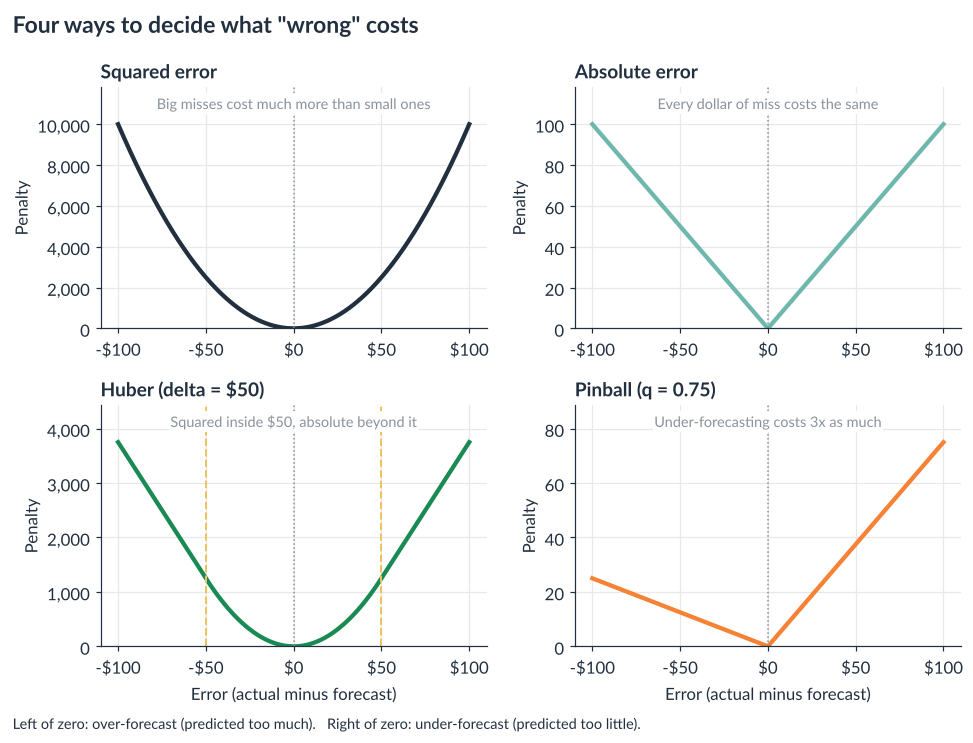

In [6]:
def squared_loss(e):
    return np.asarray(e, dtype=float) ** 2

def absolute_loss(e):
    return np.abs(np.asarray(e, dtype=float))

def huber_loss(e, delta):
    # Squared for small misses, absolute for big ones. delta is where it switches.
    e = np.asarray(e, dtype=float)
    a = np.abs(e)
    return np.where(a <= delta, 0.5 * e**2, delta * (a - 0.5 * delta))

def pinball_loss(e, q):
    # Error = actual - forecast. Under-forecasts (positive errors) cost q per unit,
    # over-forecasts (negative errors) cost (1 - q) per unit.
    e = np.asarray(e, dtype=float)
    return np.where(e >= 0, q * e, (q - 1) * e)

e = np.linspace(-100, 100, 401)
d = L["huber_delta_order"]
panels = [
    ("Squared error", squared_loss(e), "squared", "Big misses cost much more than small ones"),
    ("Absolute error", absolute_loss(e), "absolute", "Every dollar of miss costs the same"),
    (f"Huber (delta = ${d})", huber_loss(e, d), "huber", f"Squared inside ${d}, absolute beyond it"),
    (f"Pinball (q = {Q:.2f})", pinball_loss(e, Q), "pinball", f"Under-forecasting costs {Q/(1-Q):.0f}x as much"),
]
fig, axes = plt.subplots(2, 2, figsize=(9, 6.6))
for ax, (name, pen, key, note) in zip(axes.flat, panels):
    ax.plot(e, pen, color=LOSS_COLORS[key], lw=2.8)
    ax.axvline(0, color=GRAY, lw=1, ls=":")
    if key == "huber":
        for s in (-d, d):
            ax.axvline(s, color=GOLD, lw=1.3, ls="--")
    ax.set_title(name, fontsize=12.5)
    ax.text(0.5, 0.97, note, transform=ax.transAxes, ha="center", va="top", fontsize=9.5, color=GRAY,
            bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.set_xticks([-100, -50, 0, 50, 100])
    ax.xaxis.set_major_formatter(dollars)
    ax.set_ylabel("Penalty")
    ax.yaxis.set_major_formatter(lambda x, pos: f"{x:,.0f}")
    ax.set_ylim(0, pen.max() * 1.18)
for ax in axes[1]:
    ax.set_xlabel("Error (actual minus forecast)")
fig.text(0.02, -0.01, "Left of zero: over-forecast (predicted too much).   Right of zero: under-forecast (predicted too little).",
         fontsize=9.5, color=NAVY)
fig.suptitle("Four ways to decide what \"wrong\" costs", x=0.02, ha="left", fontsize=15, fontweight="bold", color=NAVY)
fig.tight_layout()
save(fig, "fig01_loss_shapes.png")
plt.show()

# Family 1: Regression losses

The first three parts predict numbers: the size of a typical order, the revenue an ad dollar brings back, and how many boxes to prepare each week.

## 3. Part 1: One number, four answers

Let's start with the simplest forecast there is: one number, with no predictors. The shop has 500 recent orders, and I want the single best guess for "a typical order." Most orders are everyday gift boxes around \$60. Six are corporate gift orders between \$1,500 and \$4,000.

For each loss, the code below tries candidate forecasts and keeps the one with the smallest total loss across all 500 orders. Nothing else changes between the four runs.

In [7]:
r1 = np.random.default_rng(SEED)
n_every = D["n_orders"] - D["n_big_orders"]
everyday = D["typical_order"] * np.exp(r1.normal(0, D["order_spread"], n_every))
corporate = r1.uniform(*D["big_order_range"], D["n_big_orders"])
orders = np.round(np.concatenate([everyday, corporate]), 2)
is_corporate = np.r_[np.zeros(n_every, bool), np.ones(D["n_big_orders"], bool)]

def part1_losses():
    return {
        "Squared error": (squared_loss, "squared"),
        "Absolute error": (absolute_loss, "absolute"),
        f"Huber (delta ${L['huber_delta_order']})": (lambda e: huber_loss(e, L["huber_delta_order"]), "huber"),
        f"Pinball (q = {Q:.2f})": (lambda e: pinball_loss(e, Q), "pinball"),
    }

def best_constant(y, loss):
    # Search for the single number that makes the total loss over all orders as small as possible
    res = minimize_scalar(lambda c: loss(y - c).sum(), bounds=(y.min(), y.max()),
                          method="bounded", options={"xatol": 1e-4})
    return res.x

best1 = {name: best_constant(orders, f) for name, (f, _) in part1_losses().items()}
best1_small = {name: best_constant(orders[~is_corporate], f) for name, (f, _) in part1_losses().items()}

print(f"{len(orders)} orders, {is_corporate.sum()} corporate | total ${orders.sum():,.0f}")
print(f"Mean ${orders.mean():.2f} | median ${np.median(orders):.2f} | "
      f"{Q:.0%} quantile ${np.quantile(orders, Q):.2f} | largest ${orders.max():,.0f}")
for name in best1:
    print(f"  {name:22s} best single forecast ${best1[name]:7.2f}   without corporate orders ${best1_small[name]:6.2f}")

500 orders, 6 corporate | total $48,816
Mean $97.63 | median $60.86 | 75% quantile $79.56 | largest $3,641
  Squared error          best single forecast $  97.63   without corporate orders $ 65.78
  Absolute error         best single forecast $  60.85   without corporate orders $ 60.32
  Huber (delta $50)      best single forecast $  64.40   without corporate orders $ 63.74
  Pinball (q = 0.75)     best single forecast $  79.66   without corporate orders $ 78.28


Four losses, four different "best" answers from the same 500 orders:

- **Squared error picks \$97.63, the mean.** This isn't a coincidence. The number that minimizes total squared error is always the average. The six corporate orders drag it far above what almost any customer actually spends. Only about one order in seven is bigger than \$97.63.
- **Absolute error picks \$60.85, the median.** The number that minimizes total absolute error is always the middle value. Half the orders are below it and half are above.
- **Huber loss picks \$64.40.** It lands between the two, close to the median, because the corporate orders are far beyond the \$50 switch point and get treated like absolute error.
- **Pinball loss at q = 0.75 picks \$79.66, the 75th percentile.** Three quarters of orders are at or below it. That's what pinball loss always does: it finds the quantile you ask for.

The bottom panel shows why. Each curve is the total loss for every candidate forecast, scaled to the same height so they fit on one chart. Each one bottoms out at a different place. The model doesn't decide what "typical" means. The loss does.

Saved figures/fig02_total_loss_curves.png


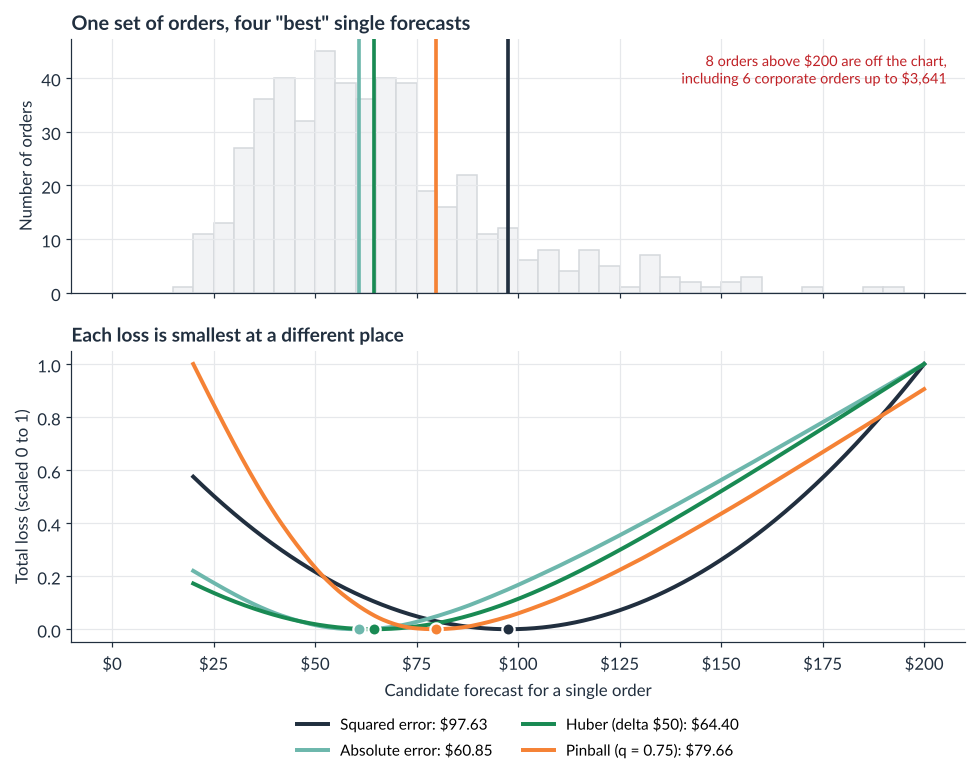

In [8]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7.2), sharex=True, gridspec_kw={"height_ratios": [1, 1.15]})
xmax = 200
ax1.hist(orders[orders <= xmax], bins=np.arange(0, xmax + 5, 5), color=CARD, edgecolor="#d5d8dc")
ax1.set_ylabel("Number of orders")
ax1.set_title("One set of orders, four \"best\" single forecasts")
n_off = (orders > xmax).sum()
ax1.text(0.98, 0.95, f"{n_off} orders above ${xmax} are off the chart,\nincluding {is_corporate.sum()} corporate orders up to ${orders.max():,.0f}",
         transform=ax1.transAxes, ha="right", va="top", fontsize=9.5, color=RED)

grid = np.linspace(20, xmax, 721)
for (name, (f, key)), ls in zip(part1_losses().items(), ["-", "-", "-", "-"]):
    c = best1[name]
    col = LOSS_COLORS[key]
    ax1.axvline(c, color=col, lw=2.4)
    tot = np.array([f(orders - g).sum() for g in grid])
    scaled = (tot - tot.min()) / (tot.max() - tot.min())
    ax2.plot(grid, scaled, color=col, lw=2.6, label=f"{name}: ${c:,.2f}")
    ax2.plot([c], [(f(orders - c).sum() - tot.min()) / (tot.max() - tot.min())], "o", color=col, ms=8,
             markeredgecolor="white", markeredgewidth=1.5, zorder=5)
ax2.set_ylabel("Total loss (scaled 0 to 1)")
ax2.set_xlabel("Candidate forecast for a single order")
ax2.xaxis.set_major_formatter(dollars)
ax2.set_title("Each loss is smallest at a different place", fontsize=12.5)
ax2.legend(loc="upper center", fontsize=10, ncol=2, bbox_to_anchor=(0.5, -0.2))
fig.tight_layout()
save(fig, "fig02_total_loss_curves.png")
plt.show()

The last column is the one I'd show a client. Take out the six corporate orders and the mean falls 33%, from \$97.63 to \$65.78. (Or, read the other way, those six orders out of 500 raise it 48%.) The median, the Huber answer, and the 75th percentile barely move, by 1% to 2%.

That doesn't make the mean wrong. If you're budgeting total revenue, the mean is exactly the number you need: 500 orders times \$97.63 is the \$48,816 the shop actually took in. The median would come up about \$18,000 short. The mean answers "how much per order, on average?" and the median answers "what does a typical customer spend?" They're different questions, and each loss is the right tool for one of them.

In [9]:
meaning = {
    "Squared error": "The mean (average) order",
    "Absolute error": "The median (middle) order",
    f"Huber (delta ${L['huber_delta_order']})": "Between the median and the mean",
    f"Pinball (q = {Q:.2f})": f"The {Q:.0%} quantile: {Q:.0%} of orders are at or below it",
}
t1 = pd.DataFrame({
    "Loss": list(best1),
    "Best single forecast": [f"${v:,.2f}" for v in best1.values()],
    "What it equals": [meaning[k] for k in best1],
    f"Without the {D['n_big_orders']} corporate orders": [f"${v:,.2f}" for v in best1_small.values()],
    "Change": [f"{(a - b) / b:+.0%}" for a, b in zip(best1.values(), best1_small.values())],
})
render_table("table01_one_number_four_answers.png", "One number, four answers",
             f"The best single forecast for a typical order, from {len(orders)} simulated orders", t1,
             [17, 12, 30, 16, 8])
t1

Saved tables/table01_one_number_four_answers.png and a CSV copy


,Loss,Best single forecast,What it equals,Without the 6 corporate orders,Change
0,Squared error,$97.63,The mean (average) order,$65.78,+48%
1,Absolute error,$60.85,The median (middle) order,$60.32,+1%
2,Huber (delta $50),$64.40,Between the median and the mean,$63.74,+1%
3,Pinball (q = 0.75),$79.66,The 75% quantile: 75% of orders are at or belo...,$78.28,+2%


## 4. Part 2: Big customers pull squared error

A single number is a good warm-up, but real forecasts use predictors. Here the shop wants to know what its advertising returns. It has two years of weekly data: ad spend and revenue. We'll fit the same straight-line model to it three times, once with each loss:

**revenue = baseline + (revenue per ad dollar) x ad spend**

The slope, **revenue per extra ad dollar**, is the marginal return from the last article. It's exactly the kind of number the budget optimizer relied on. If it's too high, the optimizer spends too much. A real marketing model would use curved response functions, but a straight line keeps the focus on the loss.

Here's the catch built into the data. The shop spends more on ads during the holiday season (weeks 47 to 52), which is how most small businesses plan. The corporate gift orders also arrive during the holidays. They come from long-standing business relationships, not from the ads. But they land in the same weeks the ad budget is highest, and a model can't tell the difference on its own.

The fitting function below is the heart of the notebook. It fits the same model to the same data, and only the loss changes. Behind the scenes, each loss uses the solver that suits it. Squared error has an exact formula. Absolute and pinball losses can be solved exactly as a linear program. Huber loss is smooth, so a standard numerical minimizer handles it. Section 8 checks the results against scikit-learn.

In [10]:
def fit_linear(X, y, loss, q=0.5, delta=1.0):
    """Fit forecast = b0 + b1*x1 + b2*x2 + ... by minimizing the chosen loss.
    Returns [intercept, slope1, slope2, ...]. Only the loss changes between fits."""
    X = np.asarray(X, dtype=float).reshape(len(y), -1)
    y = np.asarray(y, dtype=float)
    A = np.column_stack([np.ones(len(y)), X])

    if loss == "squared":
        # Squared error has an exact answer (ordinary least squares)
        return np.linalg.lstsq(A, y, rcond=None)[0]

    if loss in ("absolute", "pinball"):
        # Absolute and pinball losses can be solved exactly as a linear program.
        # Each error is split into an under-forecast part u and an over-forecast part v.
        q = 0.5 if loss == "absolute" else q
        n, p = A.shape
        cost = np.r_[np.zeros(p), np.full(n, q), np.full(n, 1 - q)]
        A_eq = np.hstack([A, np.eye(n), -np.eye(n)])
        bounds = [(None, None)] * p + [(0, None)] * (2 * n)
        res = linprog(cost, A_eq=A_eq, b_eq=y, bounds=bounds, method="highs")
        if not res.success:
            raise RuntimeError(f"{loss} fit failed: {res.message}")
        return res.x[:p]

    if loss == "huber":
        # Huber loss is smooth, so a standard numerical minimizer works.
        # Features are standardized inside the fit to keep the numbers well scaled.
        mu, sd = X.mean(0), X.std(0)
        sd[sd == 0] = 1
        Z = np.column_stack([np.ones(len(y)), (X - mu) / sd])
        k = len(y) * delta
        def f(b):
            e = y - Z @ b
            return huber_loss(e, delta).sum() / k, -(Z.T @ np.clip(e, -delta, delta)) / k
        b0 = np.linalg.lstsq(Z, y, rcond=None)[0]
        res = minimize(f, b0, jac=True, method="BFGS", options={"gtol": 1e-9, "maxiter": 10000})
        slopes = res.x[1:] / sd
        return np.r_[res.x[0] - slopes @ mu, slopes]

    raise ValueError(f"Unknown loss: {loss}")

def predict(beta, X):
    X = np.asarray(X, dtype=float).reshape(len(X), -1)
    return beta[0] + X @ beta[1:]

Now simulate the two years, fit the three models, and plot them. In this simulation the true revenue per ad dollar is \$1.80, and we know that only because we built the data.

In [11]:
def weekly_calendar(n_weeks, rng):
    # Holiday weeks (47 to 52) get a bigger ad budget, which is how most small shops plan.
    week = np.tile(np.arange(1, 53), int(np.ceil(n_weeks / 52)))[:n_weeks]
    holiday = week >= 47
    spend = rng.uniform(600, 2400, n_weeks) + holiday * rng.uniform(600, 1200, n_weeks)
    return week, holiday, np.round(spend, 0)

r2 = np.random.default_rng(SEED + 1)
week2, holiday2, spend2 = weekly_calendar(D["weeks_history"], r2)
everyday_rev = D["base_revenue"] + D["true_revenue_per_ad_dollar"] * spend2 + r2.normal(0, D["revenue_noise"], len(spend2))

# Corporate gift orders arrive in holiday weeks. They come from relationships, not ads,
# but they land in the same weeks the ad budget is highest.
holiday_idx = r2.permutation(np.flatnonzero(holiday2))   # the order in which holiday weeks get a corporate order
corporate_bump = r2.uniform(*D["big_week_range"], len(holiday_idx))

def revenue_with(n_big):
    rev = everyday_rev.copy()
    rev[holiday_idx[:n_big]] += corporate_bump[:n_big]
    return rev

revenue2 = revenue_with(D["n_big_weeks"])
big_week = np.zeros(len(spend2), bool); big_week[holiday_idx[:D["n_big_weeks"]]] = True

PART2 = {
    "Squared error": dict(loss="squared"),
    "Absolute error": dict(loss="absolute"),
    f"Huber (delta ${L['huber_delta_revenue']:,})": dict(loss="huber", delta=L["huber_delta_revenue"]),
}
PART2_KEYS = ["squared", "absolute", "huber"]
fits2 = {name: fit_linear(spend2, revenue2, **kw) for name, kw in PART2.items()}

print(f"{len(spend2)} weeks | {holiday2.sum()} holiday weeks | {big_week.sum()} include a corporate order")
print(f"Average weekly spend ${spend2.mean():,.0f} (holiday ${spend2[holiday2].mean():,.0f}) | "
      f"average weekly revenue ${revenue2.mean():,.0f}")
for name, b in fits2.items():
    print(f"  {name:22s} intercept ${b[0]:7,.0f}   revenue per extra ad dollar ${b[1]:.2f}")

104 weeks | 12 holiday weeks | 6 include a corporate order
Average weekly spend $1,623 (holiday $2,495) | average weekly revenue $5,907
  Squared error          intercept $  1,707   revenue per extra ad dollar $2.59
  Absolute error         intercept $  2,311   revenue per extra ad dollar $2.01
  Huber (delta $1,500)   intercept $  2,201   revenue per extra ad dollar $2.10


Saved figures/fig03_fits_with_outliers.png


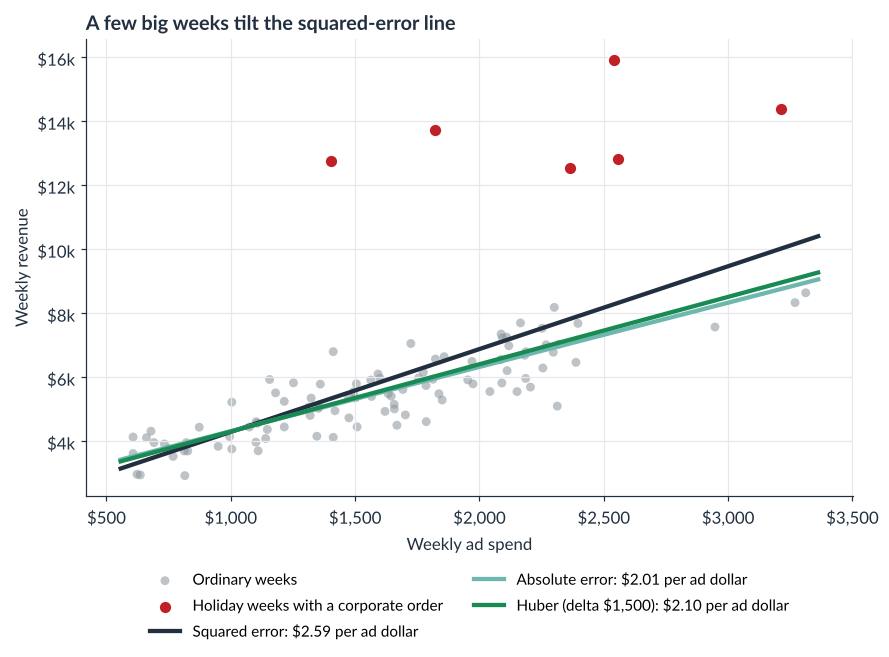

In [12]:
fig, ax = plt.subplots(figsize=(9, 5.4))
ax.scatter(spend2[~big_week], revenue2[~big_week], s=34, color=GRAY, alpha=0.55, edgecolor="none", label="Ordinary weeks")
ax.scatter(spend2[big_week], revenue2[big_week], s=70, color=RED, edgecolor="white", linewidth=1,
           label="Holiday weeks with a corporate order", zorder=4)
xs = np.linspace(spend2.min() - 50, spend2.max() + 50, 50)
for (name, b), key in zip(fits2.items(), PART2_KEYS):
    ax.plot(xs, predict(b, xs), color=LOSS_COLORS[key], lw=2.8,
            label=f"{name}: ${b[1]:.2f} per ad dollar", zorder=3)
ax.set_xlabel("Weekly ad spend")
ax.set_ylabel("Weekly revenue")
ax.xaxis.set_major_formatter(dollars)
ax.yaxis.set_major_formatter(dollars_k)
ax.set_title("A few big weeks tilt the squared-error line")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2, fontsize=10)
save(fig, "fig03_fits_with_outliers.png")
plt.show()

The squared-error line is visibly steeper. The six red weeks sit far above everything else, and squared error hates big misses so much that it tilts the whole line toward them. The absolute-error and Huber lines mostly follow the ordinary gray weeks.

To see how this builds up, the next cell refits the models while adding corporate orders one holiday week at a time, from none up to all 12 holiday weeks.

Saved figures/fig04_outlier_influence.png


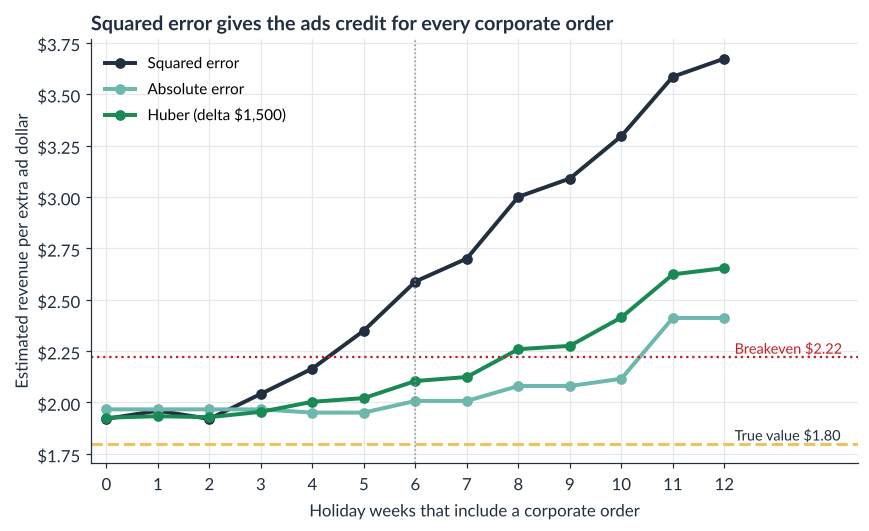

,Corporate weeks,Squared error,Absolute error,"Huber (delta $1,500)"
0,0,1.920,1.967,1.926
1,1,1.960,1.967,1.933
2,2,1.920,1.967,1.929
3,3,2.042,1.967,1.955
4,4,2.165,1.951,2.003
5,5,2.350,1.951,2.021
6,6,2.588,2.008,2.104
7,7,2.700,2.008,2.124
8,8,3.000,2.080,2.259
9,9,3.090,2.080,2.275


In [13]:
max_big = len(holiday_idx)
influence = []
for n in range(max_big + 1):
    rev = revenue_with(n)
    row = {"Corporate weeks": n}
    for name, kw in PART2.items():
        row[name] = fit_linear(spend2, rev, **kw)[1]
    influence.append(row)
influence = pd.DataFrame(influence)

fig, ax = plt.subplots(figsize=(9, 5))
for name, key in zip(PART2, PART2_KEYS):
    ax.plot(influence["Corporate weeks"], influence[name], "o-", color=LOSS_COLORS[key], lw=2.6, ms=6, label=name)
ax.axhline(D["true_revenue_per_ad_dollar"], color=GOLD, lw=2, ls="--")
ax.axhline(BREAKEVEN, color=RED, lw=1.5, ls=":")
ax.text(max_big + 0.2, D["true_revenue_per_ad_dollar"], f"True value ${D['true_revenue_per_ad_dollar']:.2f}",
        va="bottom", fontsize=9.5, color=NAVY)
ax.text(max_big + 0.2, BREAKEVEN, f"Breakeven ${BREAKEVEN:.2f}", va="bottom", fontsize=9.5, color=RED)
ax.axvline(D["n_big_weeks"], color=GRAY, lw=1, ls=":")
ax.set_xlim(-0.3, max_big + 2.6)
ax.set_xticks(range(max_big + 1))
ax.set_xlabel("Holiday weeks that include a corporate order")
ax.set_ylabel("Estimated revenue per extra ad dollar")
ax.yaxis.set_major_formatter(lambda x, pos: f"${x:.2f}")
ax.set_title("Squared error gives the ads credit for every corporate order")
ax.legend(loc="upper left", fontsize=10)
save(fig, "fig04_outlier_influence.png")
plt.show()
influence.round(3)

With no corporate orders, all three losses agree closely, between about \$1.92 and \$1.97 per ad dollar. (They're a bit above the true \$1.80 because two years of noisy weekly data is only so informative.) Then the corporate weeks start arriving. Each one moves the squared-error slope, which climbs by \$1.75 across the chart. Absolute error moves by \$0.44 and Huber by \$0.73. At the default of six corporate weeks, marked by the dotted vertical line, squared error is already well above breakeven while the other two are still below it.

The table below turns the slopes into a business verdict. At a 45% gross margin, each ad dollar has to bring back about \$2.22 in revenue to pay for itself.

In [14]:
m = C["gross_margin"]
rows = []
for name, b in fits2.items():
    profit = m * b[1] - 1
    rows.append([name, f"${b[1]:.2f}", f"{'+' if profit >= 0 else '-'}${abs(profit):.2f}",
                 "Ads pay for themselves" if profit >= 0 else "Ads lose money"])
true_profit = m * D["true_revenue_per_ad_dollar"] - 1
rows.append(["True value (known because it's simulated)", f"${D['true_revenue_per_ad_dollar']:.2f}",
             f"{'+' if true_profit >= 0 else '-'}${abs(true_profit):.2f}",
             "Ads pay for themselves" if true_profit >= 0 else "Ads lose money"])
t2 = pd.DataFrame(rows, columns=["Loss used to fit the model", "Revenue per extra ad dollar",
                                 f"Profit per extra ad dollar ({m:.0%} margin)", "What the model tells you"])
render_table("table02_revenue_per_ad_dollar.png", "Same data, different verdict on the ads",
             f"Two years of weekly data, {D['n_big_weeks']} of them with a corporate gift order", t2, [24, 13, 17, 22])
t2

Saved tables/table02_revenue_per_ad_dollar.png and a CSV copy


,Loss used to fit the model,Revenue per extra ad dollar,Profit per extra ad dollar (45% margin),What the model tells you
0,Squared error,$2.59,+$0.16,Ads pay for themselves
1,Absolute error,$2.01,-$0.10,Ads lose money
2,"Huber (delta $1,500)",$2.10,-$0.05,Ads lose money
3,True value (known because it's simulated),$1.80,-$0.19,Ads lose money


Same data, opposite conclusions. The squared-error model says each extra ad dollar earns about 16 cents in profit, so spend more. The absolute-error and Huber models say each extra dollar loses money, and the truth, which only a simulation can reveal, is that each dollar loses about 19 cents. A squared-error model handed to the last article's optimizer would have pushed the budget up, and the shop would have paid for it.

Two cautions. First, this isn't a story about squared error being bad. It's a story about what squared error targets. It gives every week's revenue full weight, including revenue the ads didn't cause. The deeper fix is to model the corporate orders separately, which is a measurement question and not a loss question. Second, robust losses aren't magic. Look at the right side of the chart: once corporate orders show up in 11 of the 12 holiday weeks, they stop being outliers and become the pattern, and even absolute error starts crediting the ads.

The loss can't tell you whether those big orders belong in the forecast. It only decides how much they get to pull.

## 5. Part 3: When one kind of miss costs more

So far, a miss in either direction has cost the same. In business, that's rare. Now the shop needs to decide how many perishable gift boxes to prepare each week. Every box has to be made before orders come in.

- **Prepare too few** and a customer can't get a box. That costs about **\$12** in lost margin and goodwill.
- **Prepare too many** and the extra boxes go to waste. That costs about **\$4** each in ingredients and labor.

Weekly demand depends on ad spend, whether there's a promotion running, and the holiday season. It's also noisier in busy weeks, which is realistic: a week that should bring 150 orders can easily bring 120 or 190, while a quiet week stays closer to its forecast.

We'll train the same model with each of the four losses on two years of weekly history, and then test each one on a third year it hasn't seen. Because the data is simulated, I can replay that test year 1,000 times with fresh random demand. That averages out the luck of any one year, so the comparison reflects each model and not a lucky draw. Each week, the shop prepares the number of boxes its forecast says.

In [15]:
def simulate_weeks(n_weeks, rng):
    week, holiday, spend = weekly_calendar(n_weeks, rng)
    promo = rng.random(n_weeks) < D["promo_share"]
    X = np.column_stack([spend / 1000, promo, holiday]).astype(float)   # ad spend in $ thousands
    mu = (D["base_demand"] + D["demand_per_1k_ad"] * X[:, 0]
          + D["promo_lift"] * X[:, 1] + D["holiday_lift"] * X[:, 2])
    return X, mu

def draw_demand(mu, rng, size=None):
    # Multiplicative noise: busier weeks are also harder to predict. Average demand equals mu.
    s = D["demand_noise"]
    shape = mu.shape if size is None else (size, len(mu))
    return np.round(mu * np.exp(rng.normal(-s**2 / 2, s, shape)))

r3 = np.random.default_rng(SEED + 2)
X_train, mu_train = simulate_weeks(D["weeks_history"], r3)
y_train = draw_demand(mu_train, r3)
X_test, mu_test = simulate_weeks(52, r3)
Y_test = draw_demand(mu_test, r3, size=D["replay_years"])   # 1,000 versions of the same test year

def business_cost(prep, demand):
    # Cost for each simulated year: boxes wasted plus orders missed, at their own prices
    wasted = np.clip(prep - demand, 0, None)
    missed = np.clip(demand - prep, 0, None)
    return (C["cost_per_box_wasted"] * wasted + C["cost_per_order_missed"] * missed).sum(axis=-1)

def evaluate(forecast):
    prep = np.round(np.clip(forecast, 0, None))
    err = Y_test - forecast
    return {
        "Average weekly prep": prep.mean(),
        "Weeks short per year": (Y_test > prep).sum(axis=1).mean(),
        "Boxes wasted per year": np.clip(prep - Y_test, 0, None).sum(axis=1).mean(),
        "Orders missed per year": np.clip(Y_test - prep, 0, None).sum(axis=1).mean(),
        "Yearly cost": business_cost(prep, Y_test).mean(),
        "RMSE": np.sqrt((err**2).mean()),
        "MAE": np.abs(err).mean(),
        "Coverage": (Y_test <= forecast).mean(),
    }

PART3 = {
    "Squared error": dict(loss="squared"),
    "Absolute error": dict(loss="absolute"),
    f"Huber (delta {L['huber_delta_boxes']} boxes)": dict(loss="huber", delta=L["huber_delta_boxes"]),
    f"Pinball (q = {Q:.2f})": dict(loss="pinball", q=Q),
}
PART3_KEYS = ["squared", "absolute", "huber", "pinball"]
fits3 = {name: fit_linear(X_train, y_train, **kw) for name, kw in PART3.items()}
res3 = pd.DataFrame({name: evaluate(predict(b, X_test)) for name, b in fits3.items()}).T

print(f"Training: {len(y_train)} weeks, average demand {y_train.mean():.0f} boxes | "
      f"test year replayed {D['replay_years']:,} times, average demand {Y_test.mean():.0f} boxes")
print(f"Target quantile q = {Q:.2f} (missed order ${C['cost_per_order_missed']}, wasted box ${C['cost_per_box_wasted']})")
res3.round(2)

Training: 104 weeks, average demand 101 boxes | test year replayed 1,000 times, average demand 100 boxes
Target quantile q = 0.75 (missed order $12, wasted box $4)


,Average weekly prep,Weeks short per year,Boxes wasted per year,Orders missed per year,Yearly cost,RMSE,MAE,Coverage
Squared error,100.46,23.03,545.07,519.34,8412.32,27.08,20.46,0.55
Absolute error,96.96,25.82,447.04,603.32,9027.98,27.13,20.21,0.50
Huber (delta 15 boxes),98.31,25.16,496.66,582.93,8981.77,27.71,20.75,0.51
Pinball (q = 0.75),116.04,13.21,1098.89,263.16,7553.52,33.40,26.21,0.74


The first table already tells the story, and the rest of this section unpacks it.

Here's the key idea. Should you prepare one more box? It costs \$4 if it goes unsold and saves \$12 if a customer wants it. So it's worth preparing whenever the chance of selling it is above \$4 / (\$12 + \$4), or 25%. That means you should prepare enough boxes to cover demand in about 75% of weeks, and stop there. In forecasting terms, you want the **75th percentile** of demand, not the average. This is a classic result in operations research called the **newsvendor problem**, and the target is

**q = cost of a missed order / (cost of a missed order + cost of a wasted box) = \$12 / (\$12 + \$4) = 0.75**

Pinball loss with q = 0.75 aims at exactly that. In fact, it's the business cost itself, scaled down by a constant: \$4 per box wasted and \$12 per order missed is just 16 times the pinball penalty of 0.25 per unit over and 0.75 per unit under. When you train with that loss, you're training the model on the business's actual costs.

To check that the cost ratio really points to the cheapest forecast, the next cell trains a pinball model at every quantile from 0.05 to 0.95 and measures each one's yearly cost over the replayed test years.

Saved figures/fig05_cost_by_quantile.png


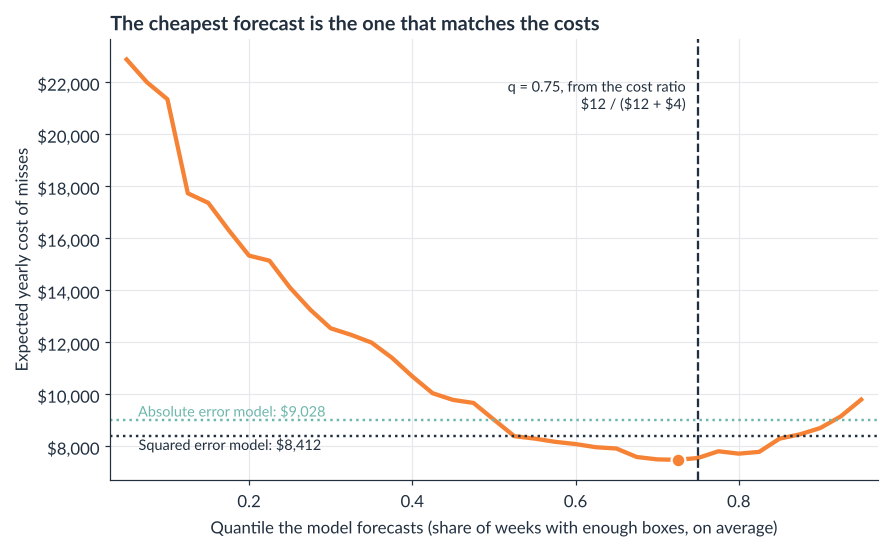

Lowest-cost quantile on the grid: 0.725 (cost $7,482) | from the cost ratio: 0.750


In [16]:
qgrid = L["quantile_grid"]
qfits = {q: fit_linear(X_train, y_train, "pinball", q=q) for q in qgrid}
qcost = pd.Series({q: evaluate(predict(b, X_test))["Yearly cost"] for q, b in qfits.items()})
q_best = qcost.idxmin()

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.plot(qcost.index, qcost.values, color=ORANGE, lw=2.8, label="Pinball loss at each quantile")
ax.plot([q_best], [qcost[q_best]], "o", color=ORANGE, ms=9, markeredgecolor="white", markeredgewidth=1.5, zorder=5)
ax.axvline(Q, color=NAVY, lw=1.5, ls="--")
ax.text(Q - 0.015, qcost.max() * 0.97, f"q = {Q:.2f}, from the cost ratio\n${C['cost_per_order_missed']} / (${C['cost_per_order_missed']} + ${C['cost_per_box_wasted']})",
        fontsize=9.5, color=NAVY, va="top", ha="right")
for name, key in zip(["Squared error", "Absolute error"], ["squared", "absolute"]):
    v = res3.loc[name, "Yearly cost"]
    ax.axhline(v, color=LOSS_COLORS[key], lw=1.6, ls=":")
    ax.text(0.06, v, f" {name} model: ${v:,.0f}", fontsize=9.5, color=LOSS_COLORS[key],
            va="bottom" if key == "absolute" else "top")
ax.set_xlabel("Quantile the model forecasts (share of weeks with enough boxes, on average)")
ax.set_ylabel("Expected yearly cost of misses")
ax.yaxis.set_major_formatter(dollars)
ax.set_xlim(0.03, 0.97)
ax.set_title("The cheapest forecast is the one that matches the costs")
save(fig, "fig05_cost_by_quantile.png")
plt.show()
print(f"Lowest-cost quantile on the grid: {q_best:.3f} (cost ${qcost[q_best]:,.0f}) | from the cost ratio: {Q:.3f}")

The cost curve bottoms out at q = 0.725, right next to the 0.75 the cost ratio predicted. (The small gap comes from training on only two years of history.) Forecasting too low is expensive, because every missed order costs \$12. Forecasting too high costs less per box, but it adds up. And the floor of the curve is fairly flat, so being roughly right about the cost ratio gets you most of the savings.

The dotted lines show where the squared-error and absolute-error models land. Both are well above the floor.

Saved figures/fig06_cost_by_loss.png


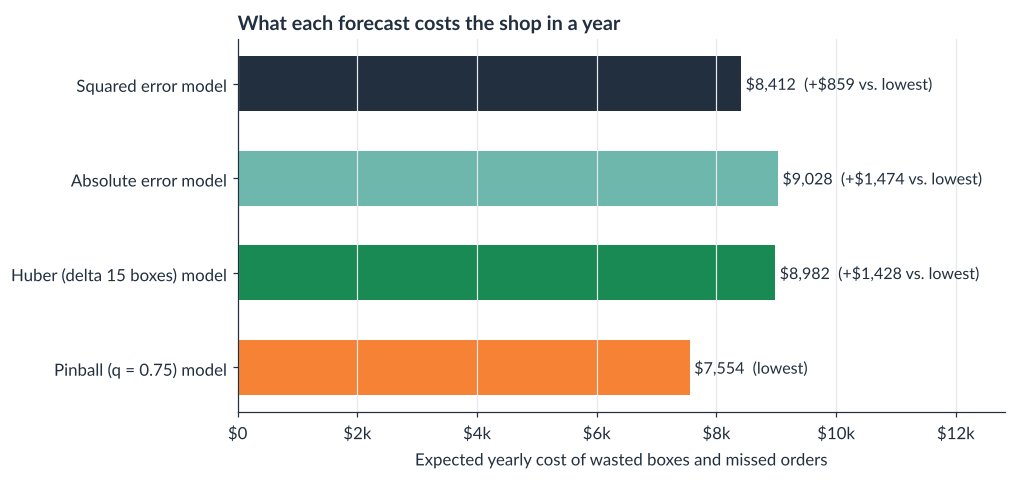

In [17]:
fig, ax = plt.subplots(figsize=(9, 4.4))
names = list(res3.index)
y = np.arange(len(names))[::-1]
vals = res3["Yearly cost"].values
ax.barh(y, vals, color=[LOSS_COLORS[k] for k in PART3_KEYS], height=0.58)
best = vals.min()
for yi, v in zip(y, vals):
    extra = "lowest" if np.isclose(v, best) else f"+${v - best:,.0f} vs. lowest"
    ax.text(v + best * 0.01, yi, f"${v:,.0f}  ({extra})", va="center", fontsize=10.5, color=NAVY)
ax.set_yticks(y); ax.set_yticklabels([f"{n} model" for n in names])
ax.xaxis.set_major_formatter(dollars_k)
ax.set_xlim(0, vals.max() * 1.42)
ax.set_xlabel("Expected yearly cost of wasted boxes and missed orders")
ax.set_title("What each forecast costs the shop in a year")
ax.grid(axis="y", visible=False)
save(fig, "fig06_cost_by_loss.png")
plt.show()

In [18]:
t3 = pd.DataFrame({
    "Model trained with": res3.index,
    "Boxes prepped per week": res3["Average weekly prep"].map(lambda v: f"{v:,.0f}"),
    "Weeks short per year": res3["Weeks short per year"].map(lambda v: f"{v:.0f} of 52"),
    "Boxes wasted per year": res3["Boxes wasted per year"].map(lambda v: f"{v:,.0f}"),
    "Orders missed per year": res3["Orders missed per year"].map(lambda v: f"{v:,.0f}"),
    "Yearly cost": res3["Yearly cost"].map(lambda v: f"${v:,.0f}"),
})
render_table("table03_forecast_decisions.png", "How the loss changes the weekly prep decision",
             f"Missed order ${C['cost_per_order_missed']}, wasted box ${C['cost_per_box_wasted']}; "
             f"averaged over {D['replay_years']:,} simulated test years", t3, [21, 11, 11, 11, 11, 10])

rank = lambda col: res3[col].rank(method="min").astype(int)
t4 = pd.DataFrame({
    "Model trained with": res3.index,
    "RMSE (boxes)": [f"{v:.1f}  (#{r})" for v, r in zip(res3["RMSE"], rank("RMSE"))],
    "MAE (boxes)": [f"{v:.1f}  (#{r})" for v, r in zip(res3["MAE"], rank("MAE"))],
    "Yearly business cost": [f"${v:,.0f}  (#{r})" for v, r in zip(res3["Yearly cost"], rank("Yearly cost"))],
    "Weeks with enough boxes": res3["Coverage"].map(lambda v: f"{v:.0%}"),
})
render_table("table04_accuracy_vs_cost.png", "The most accurate model isn't the cheapest",
             "Each score ranked from best (#1) to worst on the same simulated test years", t4, [21, 13, 13, 16, 12])
t4

Saved tables/table03_forecast_decisions.png and a CSV copy


Saved tables/table04_accuracy_vs_cost.png and a CSV copy


,Model trained with,RMSE (boxes),MAE (boxes),Yearly business cost,Weeks with enough boxes
Squared error,Squared error,27.1 (#1),20.5 (#2),"$8,412 (#2)",55%
Absolute error,Absolute error,27.1 (#2),20.2 (#1),"$9,028 (#4)",50%
Huber (delta 15 boxes),Huber (delta 15 boxes),27.7 (#3),20.8 (#3),"$8,982 (#3)",51%
Pinball (q = 0.75),Pinball (q = 0.75),33.4 (#4),26.2 (#4),"$7,554 (#1)",74%


The pinball model prepares about 116 boxes a week, compared with about 100 for the squared-error model. It wastes twice as many boxes, 1,099 a year compared with 545. But it misses about half as many orders, 263 compared with 519, and it runs short in about 13 weeks a year instead of 23. Since a missed order costs three times a wasted box, that trade saves about \$859 a year, or 10% of the cost of misses. The absolute-error and Huber models do even worse than squared error here, because demand is skewed to the right: they aim for the middle of a lopsided distribution, which is lower than the average and further from where the costs want the forecast.

The second table is the one I find most useful. By the standard accuracy metrics, RMSE and MAE, the pinball model is the **worst** of the four. By the measure the business actually pays for, it's the **best**. Each model wins at the thing it was trained to do: the squared-error model has the best RMSE, the absolute-error model has the best MAE, and the pinball model has the lowest business cost. The lesson is simple. Score a model on the same thing you trained it for, and train it for the thing that actually costs you money.

### When the costs flip

The 75th percentile isn't a magic number. It comes from these particular costs. If waste were the expensive mistake, say overtime for staff who end up standing around, or a perishable product that costs more to make than the margin it earns, the right forecast would fall below the median. The next cell tries six different cost ratios and finds the lowest-cost quantile for each.

Saved figures/fig07_best_quantile_by_cost_ratio.png


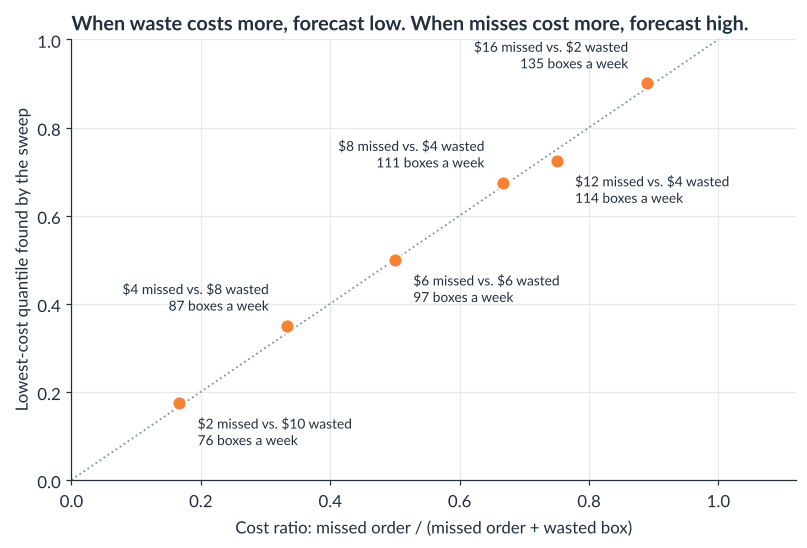

,Missed order,Wasted box,Cost ratio q,Best quantile,Boxes per week
0,2,10,0.167,0.175,76.019
1,4,8,0.333,0.350,86.846
2,6,6,0.500,0.500,96.962
3,8,4,0.667,0.675,110.846
4,12,4,0.750,0.725,114.385
5,16,2,0.889,0.900,135.115


In [19]:
ratios = [(2, 10), (4, 8), (6, 6), (8, 4), (12, 4), (16, 2)]   # (missed order, wasted box)
rows = []
for short, waste in ratios:
    cr = short / (short + waste)
    costs = {}
    for q, b in qfits.items():
        prep = np.round(np.clip(predict(b, X_test), 0, None))
        wasted = np.clip(prep - Y_test, 0, None).sum(axis=1).mean()
        missed = np.clip(Y_test - prep, 0, None).sum(axis=1).mean()
        costs[q] = waste * wasted + short * missed
    qb = min(costs, key=costs.get)
    prep_b = np.round(np.clip(predict(qfits[qb], X_test), 0, None)).mean()
    rows.append({"Missed order": short, "Wasted box": waste, "Cost ratio q": cr, "Best quantile": qb, "Boxes per week": prep_b})
ratio_df = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.plot([0, 1], [0, 1], color=GRAY, lw=1.2, ls=":")
ax.scatter(ratio_df["Cost ratio q"], ratio_df["Best quantile"], s=90, color=ORANGE, edgecolor="white", linewidth=1.5, zorder=4)
for i, r in ratio_df.iterrows():
    right = i % 2 == 0   # alternate sides so neighboring labels don't collide
    ax.annotate(f"${r['Missed order']:.0f} missed vs. ${r['Wasted box']:.0f} wasted\n{r['Boxes per week']:.0f} boxes a week",
                (r["Cost ratio q"], r["Best quantile"]), xytext=(12, -8) if right else (-12, 8),
                textcoords="offset points", fontsize=9, color=NAVY,
                va="top" if right else "bottom", ha="left" if right else "right")
ax.set_xlim(0, 1.12); ax.set_ylim(0, 1)
ax.set_xlabel("Cost ratio: missed order / (missed order + wasted box)")
ax.set_ylabel("Lowest-cost quantile found by the sweep")
ax.set_title("When waste costs more, forecast low. When misses cost more, forecast high.")
save(fig, "fig07_best_quantile_by_cost_ratio.png")
plt.show()
ratio_df.round(3)

Every point sits on or very close to the diagonal. The lowest-cost forecast tracks the cost ratio almost exactly, from about the 18th percentile when waste costs five times as much as a miss up to the 90th percentile when a miss costs eight times as much as waste. The underlying demand data stays the same. What changes is the relative cost of the two mistakes, which sets the quantile the model is trained to predict, and weekly prep ranges from about 76 to 135 boxes as a result.

# Family 2: Classification losses

Many marketing models don't predict a number. They predict a category. Most often it's binary: will this visitor buy, will this customer churn, will this lead close? Sometimes there are several categories, like which product line a customer will buy next or which offer they'll respond to. These models usually produce a score or a probability, and a business rule turns it into an action.

## 6. Part 4: Who should see the retargeting ad?

The shop can show a retargeting ad to past website visitors. Each ad costs \$3. A visitor who comes back and buys earns about \$27 in margin, which is a typical \$60 order at the 45% gross margin. About 6% of visitors buy after seeing the ad. The question is which visitors are worth \$3.

**One important simplification.** The notebook assumes that a visitor who doesn't see the ad doesn't buy during the campaign window, so every purchase it counts is caused by the ad. Real retargeting isn't that clean. Some people would have come back and bought anyway, and an ad only earns credit for the purchases it adds. A 20% chance of buying after an ad doesn't mean the ad raised that visitor's chance by 20 points. Measuring that difference is an incrementality question, which I cover in my article on measuring lift. Here, the simplification keeps the focus on how the loss functions and decision rules behave.

Two classification losses compete here:

- **Log loss**, also called **cross-entropy**, scores a predicted probability. If a visitor buys, the penalty is small when the model gave them a high chance and large when it gave them a low one. It punishes confident wrong answers hardest: predicting a 99% chance for someone who doesn't buy costs far more than predicting 60%. This is the loss behind logistic regression, and behind most conversion and click models.
- **Hinge loss** is the loss behind support vector machines. It doesn't predict a probability at all. It only cares whether each visitor lands on the correct side of a boundary, with a little room to spare (a **margin** of 1). Once a prediction is safely on the correct side, hinge loss stops caring about it.

Both losses have versions for more than two categories. Log loss becomes categorical cross-entropy, which gives a probability to each category and penalizes the probability given to the right one. This part sticks to the binary case because it's the most common in marketing and the easiest to follow, and the cost logic carries over: with several categories, it becomes a table of what each kind of mix-up costs.

The chart below shows both binary versions. On the right, both losses are drawn against the same margin so you can compare their shapes: log loss keeps rewarding more confidence, while hinge loss goes flat at zero once the margin passes 1.

Saved figures/fig08_classification_loss_shapes.png


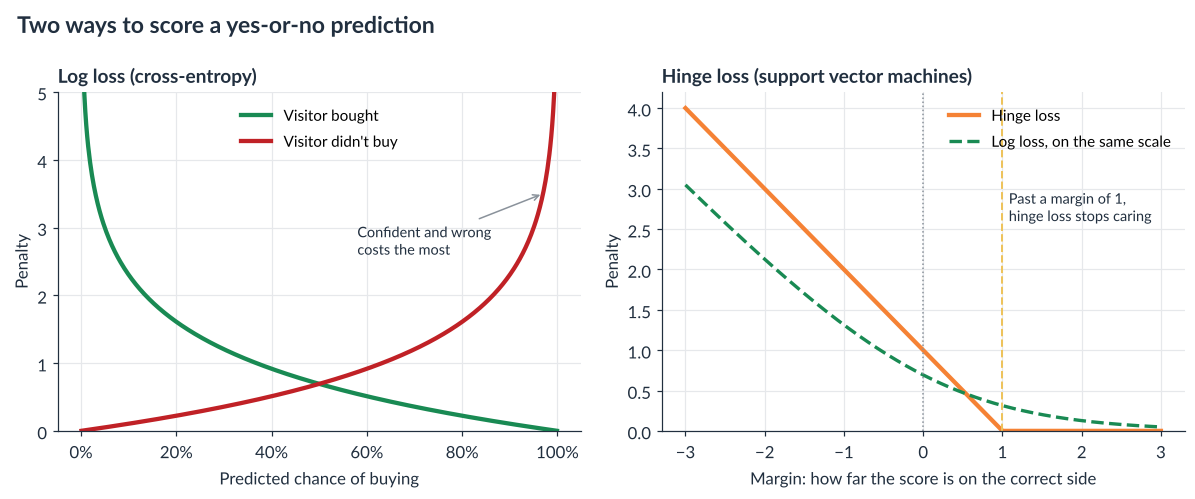

In [20]:
p = np.linspace(0.001, 0.999, 500)
m = np.linspace(-3, 3, 500)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6))

ax1.plot(p, -np.log(p), color=GREEN, lw=2.8, label="Visitor bought")
ax1.plot(p, -np.log(1 - p), color=RED, lw=2.8, label="Visitor didn't buy")
ax1.set_ylim(0, 5)
ax1.set_xlabel("Predicted chance of buying")
ax1.set_ylabel("Penalty")
ax1.xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax1.set_title("Log loss (cross-entropy)", fontsize=12.5)
ax1.annotate("Confident and wrong\ncosts the most", xy=(0.97, 3.5), xytext=(0.58, 2.6), fontsize=9.5, color=NAVY,
             arrowprops=dict(arrowstyle="->", color=GRAY))
ax1.legend(loc="upper center", fontsize=10)

ax2.plot(m, np.maximum(0, 1 - m), color=ORANGE, lw=2.8, label="Hinge loss")
ax2.plot(m, np.logaddexp(0, -m), color=GREEN, lw=2.2, ls="--", label="Log loss, on the same scale")
ax2.axvline(0, color=GRAY, lw=1, ls=":")
ax2.axvline(1, color=GOLD, lw=1.3, ls="--")
ax2.set_ylim(0, 4.2)
ax2.set_xlabel("Margin: how far the score is on the correct side")
ax2.set_ylabel("Penalty")
ax2.set_title("Hinge loss (support vector machines)", fontsize=12.5)
ax2.text(1.08, 2.6, "Past a margin of 1,\nhinge loss stops caring", fontsize=9.5, color=NAVY)
ax2.legend(loc="upper right", fontsize=10)
fig.suptitle("Two ways to score a yes-or-no prediction", x=0.02, ha="left", fontsize=15, fontweight="bold", color=NAVY)
fig.tight_layout()
save(fig, "fig08_classification_loss_shapes.png")
plt.show()

Here's the data. Each simulated visitor has five signals the shop can see: pages viewed, minutes on the site, whether they're a returning visitor, whether they added something to their cart, and whether they're on the email list. Adding to cart is the strongest signal. The models learn from 5,000 past visitors and are scored on 20,000 new ones. Results are reported per 10,000 visitors.

In [21]:
FEATURES = ["Pages viewed", "Log minutes on site", "Returning visitor", "Added to cart", "Email subscriber"]

def simulate_visitors(n, rng):
    pages = 1 + rng.poisson(D["avg_pages"] - 1, n)
    log_minutes = rng.normal(np.log(3), 0.7, n)
    returning = rng.random(n) < D["returning_share"]
    added_to_cart = rng.random(n) < np.clip(0.04 + 0.025 * np.minimum(pages, 10) + 0.08 * returning, 0, 1)
    email = rng.random(n) < D["email_share"]
    X = np.column_stack([pages, log_minutes, returning, added_to_cart, email]).astype(float)
    b = np.array(D["buy_signal"])
    p_true = 1 / (1 + np.exp(-(b[0] + X @ b[1:])))
    bought = (rng.random(n) < p_true).astype(int)
    return X, p_true, bought

r4 = np.random.default_rng(SEED + 3)
X4_train, p4_train, y4_train = simulate_visitors(D["n_visitors_train"], r4)
X4_test, p4_test, y4_test = simulate_visitors(D["n_visitors_test"], r4)
PER = 10000 / len(y4_test)   # results are reported per 10,000 visitors

def campaign(target, y, cost_per_ad=None):
    # Profit and counts when we retarget the visitors in `target`.
    cost_per_ad = C["cost_per_ad"] if cost_per_ad is None else cost_per_ad
    target = np.asarray(target, bool)
    return {
        "Visitors retargeted": target.sum() * PER,
        "Buyers reached": (target & (y == 1)).sum() * PER,
        "Ads wasted": (target & (y == 0)).sum() * PER,
        "Buyers missed": (~target & (y == 1)).sum() * PER,
        "Accuracy": (target == (y == 1)).mean(),
        "Profit": (C["margin_per_sale"] * (target & (y == 1)).sum() - cost_per_ad * target.sum()) * PER,
    }

print(f"Training: {len(y4_train):,} visitors, {y4_train.mean():.1%} bought after a retargeting ad")
print(f"Test: {len(y4_test):,} visitors, {y4_test.mean():.1%} bought")
print(f"Each ad costs ${C['cost_per_ad']}; each sale earns ${C['margin_per_sale']} in margin; "
      f"retarget when the chance of buying is above {CUTOFF:.1%}")

Training: 5,000 visitors, 6.2% bought after a retargeting ad
Test: 20,000 visitors, 6.4% bought
Each ad costs $3; each sale earns $27 in margin; retarget when the chance of buying is above 11.1%


Now fit three models. All three use the same five signals, the same straight-line (linear) score, and the same regularization setting (`C = 1`), which keeps the coefficients from growing too large. The loss is the main difference. The same setting doesn't mean exactly the same amount of regularization, since it's paired with a different loss, but it keeps the comparison as close as practical.

1. A **log-loss model** (logistic regression), which gives each visitor a probability of buying.
2. A **hinge-loss model trained the default way** (a linear support vector machine).
3. A **hinge-loss model weighted by the costs**. Missing a buyer costs \$24 in net margin and wasting an ad costs \$3, so each buyer in the training data counts 8 times as much. This is the standard way to make a hinge model cost-aware.

Then compare five decision rules: retarget everyone, use the log-loss model with the default 50% cutoff, use it with a cutoff set by the costs, and use each hinge model as it comes.

Where does the cost-based cutoff come from? An ad is worth showing when its expected margin beats its cost. A visitor with a 10% chance of buying is worth 10% x \$27 = \$2.70, which is less than the \$3 ad. A visitor with a 12% chance is worth \$3.24. The break-even point is \$3 / \$27, or about 11%. It's the same idea as the newsvendor cutoff in Part 3, applied to a yes-or-no decision. And it only works if the model gives you a probability you can trust. Log loss is designed to produce one. Hinge loss produces a score, which can be turned into a probability afterward with a technique called calibration. We'll test that at the end of this part.

In [22]:
def fit_classifier(loss, class_weight=None):
    # Same features, same linear score, and the same regularization setting (C). The loss is the main
    # difference, though the same C doesn't mean identical regularization strength across different losses.
    if loss == "log":
        model = LogisticRegression(C=L["svm_C"], max_iter=5000)
    elif loss == "hinge":
        model = LinearSVC(C=L["svm_C"], loss="hinge", dual=True, max_iter=200000, class_weight=class_weight)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConvergenceWarning)
        return make_pipeline(StandardScaler(), model).fit(X4_train, y4_train)

def cost_weights(cost_per_ad):
    # Weight each training visitor by what a mistake on them costs:
    # missing a buyer loses the net margin, retargeting a non-buyer wastes the ad.
    return {1: C["margin_per_sale"] - cost_per_ad, 0: cost_per_ad}

log_model = fit_classifier("log")
hinge_model = fit_classifier("hinge")
hinge_cost_model = fit_classifier("hinge", class_weight=cost_weights(C["cost_per_ad"]))

# Hinge scores can be turned into probabilities after training with Platt scaling,
# which fits a small logistic curve to the scores using cross-validation.
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    hinge_platt = CalibratedClassifierCV(
        make_pipeline(StandardScaler(), LinearSVC(C=L["svm_C"], loss="hinge", dual=True, max_iter=200000,
                                                  class_weight=cost_weights(C["cost_per_ad"]))),
        method="sigmoid", cv=5).fit(X4_train, y4_train)

prob = log_model.predict_proba(X4_test)[:, 1]          # log loss gives a probability
prob_platt = hinge_platt.predict_proba(X4_test)[:, 1]  # calibrated hinge probabilities
n_platt_levels = len(np.unique(prob_platt.round(4)))
score_plain = hinge_model.decision_function(X4_test)   # hinge loss gives a score, not a probability
score_cost = hinge_cost_model.decision_function(X4_test)

RULES = {
    "Retarget everyone": np.ones(len(y4_test), bool),
    "Log loss, default 50% cutoff": prob >= 0.5,
    f"Log loss, cost-based cutoff ({CUTOFF:.0%})": prob >= CUTOFF,
    "Hinge loss, trained the default way": score_plain > 0,
    "Hinge loss, weighted by the costs": score_cost > 0,
}
res4 = pd.DataFrame({name: campaign(t, y4_test) for name, t in RULES.items()}).T

predicted_profit = ((C["margin_per_sale"] * prob - C["cost_per_ad"]) * (prob >= CUTOFF)).sum() * PER
print(f"Average predicted chance of buying: {prob.mean():.1%} (actual {y4_test.mean():.1%})")
print(f"Profit the log-loss model expected before the campaign: ${predicted_profit:,.0f} per 10,000 visitors "
      f"(actual ${res4.iloc[2]['Profit']:,.0f})")
print(f"Hinge scores, default model: {np.unique(np.round(score_plain, 2))[:5]} ...")
print(f"Calibrated cost-weighted hinge model: {n_platt_levels} distinct probabilities "
      f"({', '.join(f'{v:.1%}' for v in np.unique(prob_platt.round(4))[:5])})")
res4.round(3)

Average predicted chance of buying: 6.1% (actual 6.4%)
Profit the log-loss model expected before the campaign: $5,007 per 10,000 visitors (actual $4,664)
Hinge scores, default model: [-1.] ...
Calibrated cost-weighted hinge model: 2 distinct probabilities (3.2%, 21.4%)


,Visitors retargeted,Buyers reached,Ads wasted,Buyers missed,Accuracy,Profit
Retarget everyone,10000.0,639.5,9360.5,0.0,0.064,-12733.5
"Log loss, default 50% cutoff",53.5,30.0,23.5,609.5,0.937,649.5
"Log loss, cost-based cutoff (11%)",1447.0,333.5,1113.5,306.0,0.858,4663.5
"Hinge loss, trained the default way",0.0,0.0,0.0,639.5,0.936,0.0
"Hinge loss, weighted by the costs",1597.5,334.0,1263.5,305.5,0.843,4225.5


The printout says the log-loss model expected about 6.1% of visitors to buy, and 6.4% actually did. It also forecast about \$5,007 in profit per 10,000 visitors before the campaign ran. The actual result was \$4,664, within about 7%. Neither hinge model gives a probability on its own, so neither can make that kind of forecast without an extra calibration step.

The default hinge model is the bigger surprise. It gives every visitor the same score of -1. With only 6% of visitors buying, the cheapest way to satisfy hinge loss is to predict that nobody buys. That model is right about 94% of the time, and it's useless. If you've read my article on imbalanced data, this is that problem in its purest form.

Matching the overall average isn't enough to call the probabilities trustworthy, though. A model could average 6% while overstating some visitors and understating others. Calibration is checked across groups, which is what the left side of the next chart does. I group visitors by the log-loss model's predicted chance of buying and compare each group's prediction with how many actually bought. The observed buying rates sit close to the predicted rates in every group. That's good evidence of calibration in this simulation, though not a guarantee about every individual probability.

On the right, the cost-weighted hinge model's scores pile up in two clumps, near -1 and near +1. That model learned a single rule: retarget everyone who added something to their cart. It agrees with that rule for every one of the 20,000 test visitors. It's a reasonable rule, since about 21% of cart adders buy. But it's a yes or a no, with nothing in between.

Saved figures/fig09_probabilities_vs_scores.png


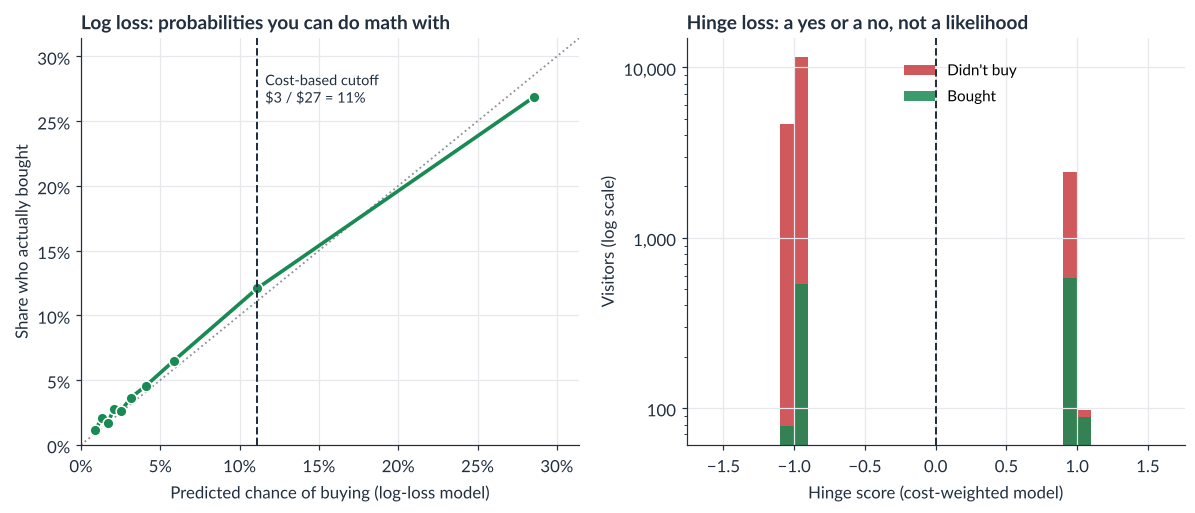

Predicted vs. actual by group: [(np.float64(0.009), np.float64(0.012)), (np.float64(0.013), np.float64(0.021)), (np.float64(0.017), np.float64(0.016)), (np.float64(0.021), np.float64(0.028)), (np.float64(0.025), np.float64(0.026)), (np.float64(0.032), np.float64(0.036)), (np.float64(0.041), np.float64(0.046)), (np.float64(0.059), np.float64(0.065)), (np.float64(0.111), np.float64(0.121)), (np.float64(0.285), np.float64(0.268))]


In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8))

# Left: are the log-loss probabilities honest? Group visitors by predicted chance and compare.
edges = np.quantile(prob, np.linspace(0, 1, 11))
bins = np.clip(np.digitize(prob, edges[1:-1]), 0, 9)
pred_bin = np.array([prob[bins == k].mean() for k in range(10)])
actual_bin = np.array([y4_test[bins == k].mean() for k in range(10)])
lim = max(pred_bin.max(), actual_bin.max()) * 1.1
ax1.plot([0, lim], [0, lim], color=GRAY, lw=1.2, ls=":")
ax1.plot(pred_bin, actual_bin, "o-", color=GREEN, lw=2.4, ms=7, markeredgecolor="white")
ax1.axvline(CUTOFF, color=NAVY, lw=1.3, ls="--")
ax1.text(CUTOFF + 0.005, lim * 0.92, f"Cost-based cutoff\n${C['cost_per_ad']} / ${C['margin_per_sale']} = {CUTOFF:.0%}",
         fontsize=9.5, color=NAVY, va="top")
ax1.set_xlim(0, lim); ax1.set_ylim(0, lim)
ax1.xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax1.yaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax1.set_xlabel("Predicted chance of buying (log-loss model)")
ax1.set_ylabel("Share who actually bought")
ax1.set_title("Log loss: probabilities you can do math with", fontsize=12.5)

# Right: the cost-weighted hinge model's scores pile up in two clumps.
ax2.hist(score_cost[y4_test == 0], bins=np.linspace(-1.6, 1.6, 33), color=RED, alpha=0.75, label="Didn't buy")
ax2.hist(score_cost[y4_test == 1], bins=np.linspace(-1.6, 1.6, 33), color=GREEN, alpha=0.85, label="Bought")
ax2.axvline(0, color=NAVY, lw=1.3, ls="--")
ax2.set_yscale("log")
ax2.yaxis.set_major_formatter(lambda x, pos: f"{x:,.0f}")
ax2.set_xlabel("Hinge score (cost-weighted model)")
ax2.set_ylabel("Visitors (log scale)")
ax2.set_title("Hinge loss: a yes or a no, not a likelihood", fontsize=12.5)
ax2.legend(loc="upper center", bbox_to_anchor=(0.55, 0.98), fontsize=10)
fig.tight_layout()
save(fig, "fig09_probabilities_vs_scores.png")
plt.show()
print("Predicted vs. actual by group:", list(zip(pred_bin.round(3), actual_bin.round(3))))

Here's what each decision rule does with 10,000 visitors.

In [24]:
t5 = pd.DataFrame({
    "Decision rule": res4.index,
    "Visitors retargeted": res4["Visitors retargeted"].map(lambda v: f"{v:,.0f}"),
    "Buyers reached": res4["Buyers reached"].map(lambda v: f"{v:,.0f}"),
    "Ads wasted": res4["Ads wasted"].map(lambda v: f"{v:,.0f}"),
    "Buyers missed": res4["Buyers missed"].map(lambda v: f"{v:,.0f}"),
    "Accuracy": res4["Accuracy"].map(lambda v: f"{v:.1%}"),
    "Profit": res4["Profit"].map(lambda v: f"-${abs(v):,.0f}" if v < 0 else f"${v:,.0f}"),
})
render_table("table05_retargeting_decisions.png", "Who should see the retargeting ad?",
             f"Per 10,000 past visitors; ad ${C['cost_per_ad']}, margin per sale ${C['margin_per_sale']}",
             t5, [24, 10, 9, 9, 9, 9, 9])
t5

Saved tables/table05_retargeting_decisions.png and a CSV copy


,Decision rule,Visitors retargeted,Buyers reached,Ads wasted,Buyers missed,Accuracy,Profit
Retarget everyone,Retarget everyone,"10,000",640,"9,360",0,6.4%,"-$12,734"
"Log loss, default 50% cutoff","Log loss, default 50% cutoff",54,30,24,610,93.7%,$650
"Log loss, cost-based cutoff (11%)","Log loss, cost-based cutoff (11%)","1,447",334,"1,114",306,85.8%,"$4,664"
"Hinge loss, trained the default way","Hinge loss, trained the default way",0,0,0,640,93.6%,$0
"Hinge loss, weighted by the costs","Hinge loss, weighted by the costs","1,598",334,"1,264",306,84.3%,"$4,226"


The table holds the most useful lesson in this part.

- **Retarget everyone** reaches every buyer and loses \$12,734, because 94% of the ads go to people who don't buy.
- **The default 50% cutoff** is the most accurate rule of the five at 93.7%. It retargets only 54 visitors and earns \$650. A 50% cutoff answers "will this person buy?" The business question is "is this ad worth \$3?"
- **The cost-based 11% cutoff** is less accurate at 85.8%, and it wastes 1,114 ads. It also reaches 334 buyers and earns \$4,664, the most of any rule.
- **The default hinge model** retargets no one and earns nothing, despite being 93.6% accurate.
- **The cost-weighted hinge model** earns \$4,226, about 91% of the log-loss result.

That last result deserves a fair reading. The cost-weighted hinge model found a simple rule that a small business could run with no model at all: retarget the cart adders. It gives up \$438 per 10,000 visitors because it can't tell a strong prospect from a weak one within each group. Sometimes a simple rule is good enough, and the extra profit from a finer model has to be weighed against the effort of building and maintaining it.

Accuracy rewards the wrong thing here, just as RMSE did in Part 3. My article on the confusion matrix covers why accuracy misleads when one outcome is rare.

The next chart sweeps the cutoff from 1% to 70% to show how much the choice matters.

Saved figures/fig10_profit_by_cutoff.png


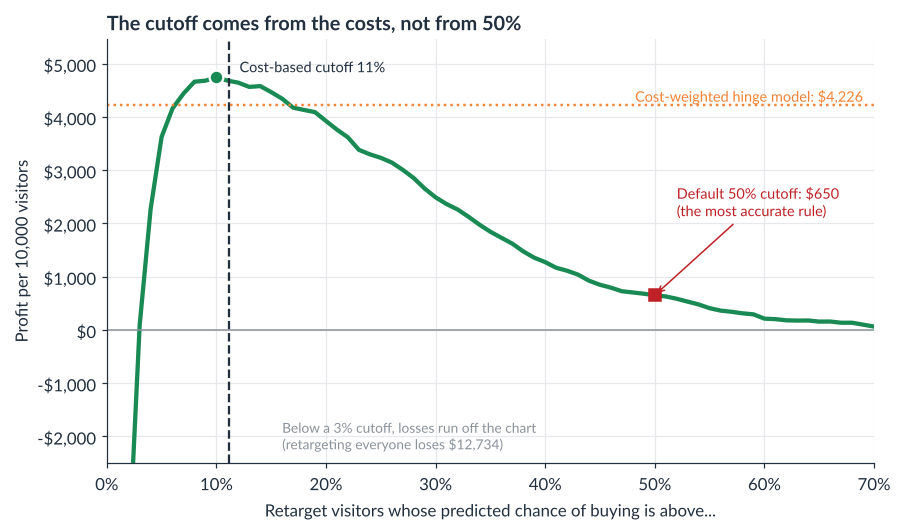

Most profitable cutoff on the grid: 10% ($4,743) | cost-based: 11.1%


In [25]:
grid = L["cutoff_grid"]
cut_profit = pd.Series({c: campaign(prob >= c, y4_test)["Profit"] for c in grid})
best_cut = cut_profit.idxmax()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(cut_profit.index, cut_profit.values, color=GREEN, lw=2.8, label="Log-loss model at each cutoff")
ax.plot([best_cut], [cut_profit[best_cut]], "o", color=GREEN, ms=9, markeredgecolor="white", markeredgewidth=1.5, zorder=5)
ax.axvline(CUTOFF, color=NAVY, lw=1.5, ls="--")
ax.text(CUTOFF + 0.01, cut_profit.max() * 1.02, f"Cost-based cutoff {CUTOFF:.0%}", fontsize=9.5, color=NAVY)
p50 = res4.loc["Log loss, default 50% cutoff", "Profit"]
ax.plot([0.5], [p50], "s", color=RED, ms=8, zorder=5)
ax.annotate(f"Default 50% cutoff: ${p50:,.0f}\n(the most accurate rule)", xy=(0.5, p50), xytext=(0.52, cut_profit.max() * 0.45),
            fontsize=9.5, color=RED, arrowprops=dict(arrowstyle="->", color=RED))
hc = res4.loc["Hinge loss, weighted by the costs", "Profit"]
ax.axhline(hc, color=ORANGE, lw=1.6, ls=":")
ax.text(0.69, hc, f"Cost-weighted hinge model: ${hc:,.0f}", fontsize=9.5, color=ORANGE, ha="right", va="bottom")
ax.axhline(0, color=GRAY, lw=1)
ax.set_xlabel("Retarget visitors whose predicted chance of buying is above...")
ax.set_ylabel("Profit per 10,000 visitors")
ax.xaxis.set_major_formatter(lambda x, pos: f"{x:.0%}")
ax.yaxis.set_major_formatter(dollars)
ax.set_xlim(0, 0.7)
ax.set_ylim(-2500, cut_profit.max() * 1.15)
ax.text(0.16, -2300, f"Below a {cut_profit[cut_profit > -2500].index.min():.0%} cutoff, losses run off the chart\n(retargeting everyone loses ${abs(res4.iloc[0]['Profit']):,.0f})",
        fontsize=9, color=GRAY, va="bottom")
ax.set_title("The cutoff comes from the costs, not from 50%")
save(fig, "fig10_profit_by_cutoff.png")
plt.show()
print(f"Most profitable cutoff on the grid: {best_cut:.0%} (${cut_profit[best_cut]:,.0f}) | cost-based: {CUTOFF:.1%}")

The most profitable cutoff in this particular test sample was 10%, slightly below the 11.1% the cost calculation predicts. That gap reflects random variation in who actually bought and small errors in the fitted probabilities. I'd still use the cost-based cutoff. Picking 10% because it did best on the test data would mean tuning the decision on the very data meant to evaluate it. Profit falls off quickly below the best cutoff, because the shop starts paying for visitors who rarely buy, and more slowly above it, because the shop starts skipping visitors who would have paid for their ad. The default 50% cutoff sits far out on the right.

There's one more test, and it's the one that matters most in practice. Costs change. Ad prices rise in the fourth quarter, and margins change with the product mix. With log loss, a new cost means a new cutoff, which is simple arithmetic: new ad cost / margin. The cost-weighted hinge model has the costs built into its training, so there are two ways to update it:

1. **Retrain it** with new cost weights every time the costs change.
2. **Calibrate it once.** Platt scaling fits a small logistic curve to the hinge scores, turning them into probabilities. Then the cutoff can move with the costs, just like the log-loss model.

The next cell tries ad costs from \$1 to \$10 all three ways.

Saved figures/fig11_profit_by_ad_cost.png


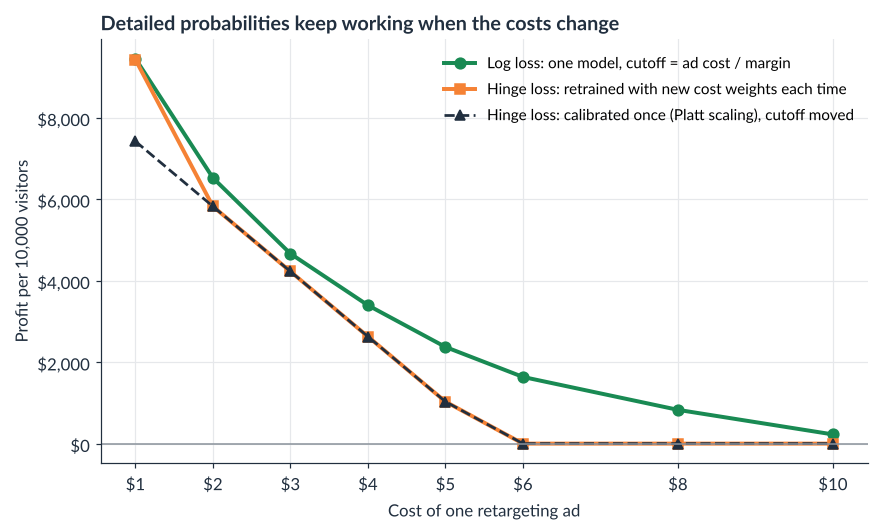

,Ad cost,Cutoff,Log loss profit,Hinge profit,Calibrated hinge profit,Hinge visitors retargeted
0,1,0.037,9450.5,9426.5,7420.5,3574.0
1,2,0.074,6523.0,5823.0,5823.0,1597.5
2,3,0.111,4663.5,4225.5,4225.5,1597.5
3,4,0.148,3396.0,2628.0,2628.0,1597.5
4,5,0.185,2372.5,1030.5,1030.5,1597.5
5,6,0.222,1636.5,0.0,0.0,0.0
6,8,0.296,829.0,0.0,0.0,0.0
7,10,0.370,225.5,0.0,0.0,0.0


In [26]:
rows = []
for ad_cost in L["ad_cost_grid"]:
    cutoff = ad_cost / C["margin_per_sale"]
    # Log loss: same model, new cutoff (just arithmetic)
    log_p = campaign(prob >= cutoff, y4_test, ad_cost)["Profit"]
    # Hinge loss: the costs live inside the training, so the model has to be retrained
    m = fit_classifier("hinge", class_weight=cost_weights(ad_cost))
    s = m.decision_function(X4_test)
    hinge_res = campaign(s > 0, y4_test, ad_cost)
    # Calibrated hinge: one model trained at the original cost, with its probabilities moved to the new cutoff
    platt_p = campaign(prob_platt >= cutoff, y4_test, ad_cost)["Profit"]
    rows.append({"Ad cost": ad_cost, "Cutoff": cutoff, "Log loss profit": log_p,
                 "Hinge profit": hinge_res["Profit"], "Calibrated hinge profit": platt_p,
                 "Hinge visitors retargeted": hinge_res["Visitors retargeted"]})
adcost = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(adcost["Ad cost"], adcost["Log loss profit"], "o-", color=GREEN, lw=2.6, ms=7,
        label="Log loss: one model, cutoff = ad cost / margin")
ax.plot(adcost["Ad cost"], adcost["Hinge profit"], "s-", color=ORANGE, lw=2.6, ms=7,
        label="Hinge loss: retrained with new cost weights each time")
ax.plot(adcost["Ad cost"], adcost["Calibrated hinge profit"], "^--", color=NAVY, lw=1.8, ms=7,
        label="Hinge loss: calibrated once (Platt scaling), cutoff moved")
ax.axhline(0, color=GRAY, lw=1)
ax.set_xticks(L["ad_cost_grid"])
ax.xaxis.set_major_formatter(dollars)
ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel("Cost of one retargeting ad")
ax.set_ylabel("Profit per 10,000 visitors")
ax.set_title("Detailed probabilities keep working when the costs change")
ax.legend(loc="upper right", fontsize=10)
save(fig, "fig11_profit_by_ad_cost.png")
plt.show()
adcost.round(3)

The log-loss model matches or beats both hinge approaches at every ad cost. At \$5 it earns \$2,373 per 10,000 visitors, against \$1,031 for the retrained hinge model. From \$6 up, both hinge approaches stop retargeting anyone, while the log-loss model keeps finding a smaller group worth the price: \$1,637 at \$6 and \$226 even at \$10.

Calibration does what it promises. The calibrated hinge model can move its cutoff without retraining. But it earns exactly the same as the retrained model from \$2 up, and less at \$1 (\$7,420 vs. \$9,427). The reason is in the right side of the earlier chart. The hinge scores fell into two clumps, so calibration can only produce two probabilities: one for cart adders and one for everyone else. Calibration can relabel scores as probabilities, but it can't recover detail the model never learned.

So the lesson isn't that hinge loss can't support dollar decisions. It can, once its scores are calibrated. The lesson is that a dollar decision needs probabilities that are both honest and detailed. Log loss is designed to produce exactly that. Hinge loss is designed to draw a boundary, and here the boundary it drew was too coarse to be worth much more than a simple rule.

These results come from one simulated business and two particular model setups, and support vector machines can do well with richer signals. But when a decision has dollars attached, most marketers are better served by a model that gives a calibrated, detailed probability, with the decision rule set separately from the costs.

## 7. Part 5: Which kind of error hurts your business more?

Here's how I'd match a loss to a business situation, for both families. The right loss isn't the one with the best reputation. It's the one whose idea of "wrong" matches what a miss actually costs you.

In [27]:
sq, ab, hu, pb = list(res3.index)
b_sq = fits2["Squared error"][1]
# A 10% to 90% range from two pinball models: how often does next year's demand land inside it?
lo, hi = predict(qfits[0.1], X_test), predict(qfits[0.9], X_test)
band_cover = ((Y_test >= lo) & (Y_test <= hi)).mean()
band_width = (hi - lo).mean()
low_case = ratio_df.iloc[1]
r_cut, r_50 = res4.iloc[2], res4.iloc[1]
hinge_zero = adcost.loc[adcost["Hinge profit"] <= 0, "Ad cost"]
biz = pd.DataFrame({
    "Business situation": [
        "Budgeting total revenue or total units",
        "Describing a typical customer or week",
        "Noisy data with an occasional giant",
        "Perishable inventory or event staffing",
        "Avoiding overspend, overstock, or overstaffing",
        "Planning for a range, not a single number",
        "Deciding who gets an ad, an offer, or a call",
        "Sorting leads into yes or no",
    ],
    "Kind of error that hurts most": [
        "Big misses, in either direction",
        "Every dollar of miss counts the same",
        "Small misses matter, giants shouldn't steer",
        "Coming up short",
        "Having too much",
        "Being surprised at either end",
        "Paying for people who won't buy vs. missing people who would",
        "Missing rare, valuable cases",
    ],
    "Loss that fits": [
        "Squared error (forecasts the mean)",
        "Absolute error (forecasts the median)",
        "Huber loss",
        "Pinball loss at a high quantile, set by the cost ratio",
        "Pinball loss at a low quantile",
        "A pair of pinball losses, such as 10% and 90%",
        "Log loss (cross-entropy), then a cutoff set by the costs",
        "Hinge loss (support vector machine), calibrated if costs matter",
    ],
    "In this simulation": [
        f"Mean order ${best1['Squared error']:,.2f}, pulled up by {D['n_big_orders']} corporate orders",
        f"Median order ${best1['Absolute error']:,.2f}, barely moved by them",
        f"${fits2[list(fits2)[2]][1]:.2f} per ad dollar vs. ${b_sq:.2f} with squared error",
        f"q = {Q:.2f} saves ${res3.loc[sq, 'Yearly cost'] - res3.loc[pb, 'Yearly cost']:,.0f} a year vs. the squared-error model",
        f"Waste at {low_case['Wasted box'] / low_case['Missed order']:.0f}x the cost of a miss: best quantile about {low_case['Best quantile']:.2f}",
        f"A 10% to 90% range about {band_width:.0f} boxes wide held {band_cover:.0%} of test weeks",
        f"{CUTOFF:.0%} cutoff earns ${r_cut['Profit']:,.0f} per 10,000 visitors vs. ${r_50['Profit']:,.0f} at 50%",
        f"Default hinge model retargets no one; cost-weighted version stops working at ${hinge_zero.min():.0f} ads" if len(hinge_zero) else "Cost-weighted hinge model needs retraining for every cost change",
    ],
    "Watch out for": [
        "A few outliers can steer the whole model",
        "Totals built from medians come up short",
        "The switch point (delta) is a judgment call",
        "The cost ratio has to be estimated honestly",
        "Chronic shortages that lose customers",
        "Ranges that are too narrow to be useful",
        "Probabilities drift; recheck calibration",
        "Scores aren't probabilities until calibrated",
    ],
})
biz.insert(0, "Family", ["Regression"] * 6 + ["Classification"] * 2)
render_table("table06_which_error_hurts.png", "Which kind of error hurts your business more?",
             "The model minimizes the loss. The business decides what \"wrong\" costs.",
             biz, [15, 22, 22, 24, 29, 21])
biz

Saved tables/table06_which_error_hurts.png and a CSV copy


,Family,Business situation,Kind of error that hurts most,Loss that fits,In this simulation,Watch out for
0,Regression,Budgeting total revenue or total units,"Big misses, in either direction",Squared error (forecasts the mean),"Mean order $97.63, pulled up by 6 corporate or...",A few outliers can steer the whole model
1,Regression,Describing a typical customer or week,Every dollar of miss counts the same,Absolute error (forecasts the median),"Median order $60.85, barely moved by them",Totals built from medians come up short
2,Regression,Noisy data with an occasional giant,"Small misses matter, giants shouldn't steer",Huber loss,$2.10 per ad dollar vs. $2.59 with squared error,The switch point (delta) is a judgment call
3,Regression,Perishable inventory or event staffing,Coming up short,"Pinball loss at a high quantile, set by the co...",q = 0.75 saves $859 a year vs. the squared-err...,The cost ratio has to be estimated honestly
4,Regression,"Avoiding overspend, overstock, or overstaffing",Having too much,Pinball loss at a low quantile,Waste at 2x the cost of a miss: best quantile ...,Chronic shortages that lose customers
5,Regression,"Planning for a range, not a single number",Being surprised at either end,"A pair of pinball losses, such as 10% and 90%",A 10% to 90% range about 69 boxes wide held 83...,Ranges that are too narrow to be useful
6,Classification,"Deciding who gets an ad, an offer, or a call",Paying for people who won't buy vs. missing pe...,"Log loss (cross-entropy), then a cutoff set by...","11% cutoff earns $4,664 per 10,000 visitors vs...",Probabilities drift; recheck calibration
7,Classification,Sorting leads into yes or no,"Missing rare, valuable cases","Hinge loss (support vector machine), calibrate...",Default hinge model retargets no one; cost-wei...,Scores aren't probabilities until calibrated


A few notes on reading the table.

In the regression rows, the first two aren't competitors. Squared error forecasts the mean, which is the right target when you'll add forecasts up into totals for a budget, a revenue plan, or an inventory order across many products. Absolute error forecasts the median, which better describes a typical customer or week. Plenty of reports quote an "average order value" that almost no customer actually places.

The pinball rows are worth knowing about. Train two pinball models, one at the 10th percentile and one at the 90th, and you get a range instead of a single number. In this simulation, that range averaged about 69 boxes wide and held 83% of the test weeks, close to the 80% it promised. A range is often more honest than a single forecast, and easier to plan around.

The classification rows follow the same pattern as Part 3. The loss produces the prediction, and the business costs set the decision. With log loss, you keep those two steps separate: one model, and a cutoff you can recalculate whenever the costs move. A cost-weighted hinge model blends the two steps together. Calibration can separate them again, but only as finely as the model's scores allow.

And the "Watch out for" column is a reminder that choosing a loss doesn't end the thinking. The Huber switch point and the cost ratio are judgment calls, the cost of a missed order includes customer goodwill, and probabilities drift as customers change, so calibration needs checking now and then. You don't need precise numbers, though. The cost curves in Parts 3 and 4 were fairly flat near their best points, so a reasonable estimate gets you most of the way.

## 8. Checking the results

A check that every result in the notebook does what the text claims. If any check fails, this cell stops with an error. The checks come in two kinds, labeled in the `Type` column.

**Math checks** should pass under any settings. They confirm that:

- In Part 1, squared error, absolute error, and pinball loss pick the mean, the median, and the 75th percentile.
- My hand-built regression fits match scikit-learn's `LinearRegression` and `QuantileRegressor` on the Part 2 and Part 3 data, and both Huber fits reached a true minimum.
- The Part 3 business cost equals pinball loss times a constant.

**Simulation results** confirm what these particular simulated data show, so they can change if you change the settings. They confirm that:

- In Part 1, Huber lands between the median and the mean.
- In Part 2, corporate orders move the squared-error slope more than the others, and absolute error stays closer to the true slope.
- In Part 3, the q = 0.75 forecast covers about 75% of test weeks, the pinball model has the lowest business cost, the squared-error model has the lowest RMSE, and the lowest-cost quantile sits near the cost ratio for every ratio tried.
- In Part 4, the log-loss probabilities are well calibrated and forecast the campaign's profit, the cost-based cutoff beats every other rule on profit, the 50% cutoff is more accurate but less profitable, the most profitable cutoff sits near the cost-based one, the default hinge model retargets fewer visitors, and log loss matches or beats both hinge approaches at every ad cost.

A simulation result shows that the notebook produced the example it describes. It doesn't prove the same thing will happen with every data set.

In [28]:
checks = []
MATH, SIM = "Math", "Simulation result"
def check(name, passed, detail, kind=SIM):
    # Math checks should pass under any settings. Simulation results describe what these
    # particular simulated data show and can change if you change the settings.
    checks.append({"Type": kind, "Check": name, "Passed": bool(passed), "Detail": detail})

# Part 1: the single best numbers match the textbook answers. We compare total loss, not location,
# because absolute and pinball losses can be flat between two neighboring orders.
lf = part1_losses()
n_sq, n_ab, n_hu, n_pb = list(lf)
check("Squared error picks the mean", abs(best1[n_sq] - orders.mean()) < 0.01,
      f"${best1[n_sq]:.2f} vs. ${orders.mean():.2f}", MATH)
check("Absolute error picks the median",
      lf[n_ab][0](orders - best1[n_ab]).sum() <= lf[n_ab][0](orders - np.median(orders)).sum() + 0.01,
      f"${best1[n_ab]:.2f} vs. ${np.median(orders):.2f}", MATH)
q_ref = np.quantile(orders, Q, method="inverted_cdf")
check(f"Pinball loss picks the {Q:.0%} quantile",
      lf[n_pb][0](orders - best1[n_pb]).sum() <= lf[n_pb][0](orders - q_ref).sum() + 0.01,
      f"${best1[n_pb]:.2f} vs. ${q_ref:.2f}", MATH)
check("Huber lands between the median and the mean", np.median(orders) <= best1[n_hu] <= orders.mean(),
      f"${np.median(orders):.2f} <= ${best1[n_hu]:.2f} <= ${orders.mean():.2f}")

# Hand-built fits match scikit-learn
for nm, (X, yv, kw) in {"Part 2": (spend2, revenue2, {}), "Part 3": (X_train, y_train, {})}.items():
    Xa = np.asarray(X, float).reshape(len(yv), -1)
    ols = LinearRegression().fit(Xa, yv)
    mine = fit_linear(Xa, yv, "squared")
    check(f"{nm}: squared-error fit matches scikit-learn", np.allclose(mine, np.r_[ols.intercept_, ols.coef_], rtol=1e-6, atol=1e-6),
          "LinearRegression", MATH)
    for loss, q in [("absolute", 0.5), ("pinball", Q)]:
        sk = QuantileRegressor(quantile=q, alpha=0.0, solver="highs").fit(Xa, yv)
        mine = fit_linear(Xa, yv, loss, q=q)
        l_mine = pinball_loss(yv - predict(mine, Xa), q).sum()
        l_sk = pinball_loss(yv - sk.predict(Xa), q).sum()
        check(f"{nm}: {loss} fit matches scikit-learn", l_mine <= l_sk * (1 + 1e-6) + 1e-6,
              f"total loss {l_mine:,.3f} vs. {l_sk:,.3f}", MATH)

# Huber fits reached a minimum: the slope of the loss is essentially zero
for nm, (X, yv, delta, b) in {"Part 2": (spend2, revenue2, L["huber_delta_revenue"], fits2[list(fits2)[2]]),
                              "Part 3": (X_train, y_train, L["huber_delta_boxes"], fits3[list(fits3)[2]])}.items():
    Xa = np.column_stack([np.ones(len(yv)), np.asarray(X, float).reshape(len(yv), -1)])
    Xs = Xa / np.r_[1, np.abs(Xa[:, 1:]).max(0)]
    g = Xs.T @ np.clip(yv - Xa @ b, -delta, delta) / (len(yv) * delta)
    check(f"{nm}: Huber fit reached a minimum", np.abs(g).max() < 1e-5, f"largest scaled gradient {np.abs(g).max():.1e}", MATH)

# Part 2: outliers move squared error more than absolute error
moves = (influence.iloc[-1] - influence.iloc[0]).abs()
check("Part 2: corporate weeks move the squared-error slope the most",
      moves["Squared error"] > moves["Absolute error"] and moves["Squared error"] > moves[list(PART2)[2]],
      f"moves: squared ${moves['Squared error']:.2f}, absolute ${moves['Absolute error']:.2f}, Huber ${moves[list(PART2)[2]]:.2f}")
check("Part 2: absolute error stays closer to the true slope than squared error",
      abs(fits2["Absolute error"][1] - D["true_revenue_per_ad_dollar"]) < abs(fits2["Squared error"][1] - D["true_revenue_per_ad_dollar"]),
      f"${fits2['Absolute error'][1]:.2f} and ${fits2['Squared error'][1]:.2f} vs. true ${D['true_revenue_per_ad_dollar']:.2f}")

# Part 3: the quantile model does what it promises, and the cost-matched loss is cheapest
pb_name = list(PART3)[3]
check(f"Part 3: the q = {Q:.2f} forecast covers about {Q:.0%} of weeks", abs(res3.loc[pb_name, "Coverage"] - Q) < 0.04,
      f"{res3.loc[pb_name, 'Coverage']:.1%}")
check("Part 3: the pinball model has the lowest business cost", res3["Yearly cost"].idxmin() == pb_name,
      f"lowest: {res3['Yearly cost'].idxmin()}")
check("Part 3: the squared-error model has the lowest RMSE", res3["RMSE"].idxmin() == "Squared error",
      f"lowest: {res3['RMSE'].idxmin()}")
check("Part 3: the lowest-cost quantile is near the cost ratio", abs(q_best - Q) <= 0.05, f"{q_best:.3f} vs. {Q:.3f}")
check("Part 3: the best quantile tracks the cost ratio for every ratio tried",
      (ratio_df["Best quantile"] - ratio_df["Cost ratio q"]).abs().max() <= 0.08,
      f"largest gap {(ratio_df['Best quantile'] - ratio_df['Cost ratio q']).abs().max():.3f}")
check("Part 3: pinball loss is the business cost, rescaled",
      np.isclose(business_cost(np.full(52, 100.0), Y_test[0]),
                 (C["cost_per_order_missed"] + C["cost_per_box_wasted"]) * pinball_loss(Y_test[0] - 100.0, Q).sum()),
      f"cost = ${C['cost_per_order_missed'] + C['cost_per_box_wasted']} x pinball loss at q = {Q:.2f}", MATH)

# Part 4: probabilities are honest, and the cost-based cutoff beats the alternatives
ece = np.average(np.abs(pred_bin - actual_bin), weights=[(bins == k).mean() for k in range(10)])
check("Part 4: average predicted chance matches the actual buy rate", abs(prob.mean() - y4_test.mean()) < 0.01,
      f"{prob.mean():.1%} vs. {y4_test.mean():.1%}")
check("Part 4: log-loss probabilities are well calibrated", ece < 0.02, f"average gap {ece:.3f}")
r_all, r_50, r_cut, r_h, r_hc = [res4.iloc[i] for i in range(5)]
check("Part 4: the cost-based cutoff beats every other rule on profit",
      r_cut["Profit"] > max(r_all["Profit"], r_50["Profit"], r_h["Profit"], r_hc["Profit"]),
      f"${r_cut['Profit']:,.0f} vs. next best ${max(r_all['Profit'], r_50['Profit'], r_h['Profit'], r_hc['Profit']):,.0f}")
check("Part 4: the 50% cutoff is more accurate but less profitable",
      r_50["Accuracy"] > r_cut["Accuracy"] and r_50["Profit"] < r_cut["Profit"],
      f"accuracy {r_50['Accuracy']:.1%} vs. {r_cut['Accuracy']:.1%}")
check("Part 4: the most profitable cutoff is near the cost-based cutoff", abs(best_cut - CUTOFF) <= 0.05,
      f"{best_cut:.2f} vs. {CUTOFF:.3f}")
check("Part 4: the default hinge model retargets fewer visitors than the cost-based rule",
      r_h["Visitors retargeted"] < r_cut["Visitors retargeted"], f"{r_h['Visitors retargeted']:,.0f} vs. {r_cut['Visitors retargeted']:,.0f}")
check("Part 4: log loss matches or beats the retrained hinge model at every ad cost",
      (adcost["Log loss profit"] >= adcost["Hinge profit"] - 100).all(),
      f"smallest gap ${(adcost['Log loss profit'] - adcost['Hinge profit']).min():,.0f}")
# Tolerance: within 10% of the margin the campaign earned, so the check scales with the campaign's size
check("Part 4: the probabilities forecast the campaign's profit",
      abs(predicted_profit - r_cut["Profit"]) < 0.10 * C["margin_per_sale"] * r_cut["Buyers reached"],
      f"expected ${predicted_profit:,.0f} vs. actual ${r_cut['Profit']:,.0f}")

check("Part 4: calibrating the cost-weighted hinge model doesn't beat log loss at any ad cost",
      (adcost["Log loss profit"] >= adcost["Calibrated hinge profit"] - 100).all(),
      f"smallest gap ${(adcost['Log loss profit'] - adcost['Calibrated hinge profit']).min():,.0f}")

checks = pd.DataFrame(checks)
if not checks["Passed"].all():
    raise AssertionError("Some checks failed:\n" + checks.loc[~checks["Passed"], ["Type", "Check", "Detail"]].to_string())
n_math = (checks["Type"] == MATH).sum()
print(f"All {len(checks)} checks passed: {n_math} math checks and {len(checks) - n_math} simulation results.")
checks.sort_values("Type", kind="stable").reset_index(drop=True)

All 29 checks passed: 12 math checks and 17 simulation results.


,Type,Check,Passed,Detail
0,Math,Squared error picks the mean,True,$97.63 vs. $97.63
1,Math,Absolute error picks the median,True,$60.85 vs. $60.86
2,Math,Pinball loss picks the 75% quantile,True,$79.66 vs. $79.51
3,Math,Part 2: squared-error fit matches scikit-learn,True,LinearRegression
4,Math,Part 2: absolute fit matches scikit-learn,True,"total loss 45,088.361 vs. 45,088.361"
5,Math,Part 2: pinball fit matches scikit-learn,True,"total loss 48,007.025 vs. 48,007.025"
6,Math,Part 3: squared-error fit matches scikit-learn,True,LinearRegression
7,Math,Part 3: absolute fit matches scikit-learn,True,"total loss 1,076.786 vs. 1,076.786"
8,Math,Part 3: pinball fit matches scikit-learn,True,total loss 881.500 vs. 881.500
9,Math,Part 2: Huber fit reached a minimum,True,largest scaled gradient 7.9e-10


All of the solvers here are standard, and the checks give good reason to trust them. Absolute and pinball losses can have more than one equally good answer when the loss is flat between two data points, which is why the checks compare total loss rather than exact coefficients.

## 9. Summary

In [29]:
sq, ab, hu, pb = list(res3.index)
summary = pd.DataFrame([
    ["Part 1: Best single order forecast, squared / absolute error",
     f"${best1[list(best1)[0]]:,.2f} / ${best1[list(best1)[1]]:,.2f}"],
    ["Part 1: Huber / pinball (q = %.2f)" % Q, f"${best1[list(best1)[2]]:,.2f} / ${best1[list(best1)[3]]:,.2f}"],
    [f"Part 1: Change in the mean when the {D['n_big_orders']} corporate orders are removed",
     f"${best1[list(best1)[0]]:,.2f} to ${best1_small[list(best1)[0]]:,.2f}"],
    ["Part 2: Revenue per ad dollar, squared / absolute / Huber",
     " / ".join(f"${b[1]:.2f}" for b in fits2.values())],
    ["Part 2: True revenue per ad dollar and breakeven", f"${D['true_revenue_per_ad_dollar']:.2f} and ${BREAKEVEN:.2f}"],
    ["Part 3: Boxes prepped per week, squared error vs. pinball",
     f"{res3.loc[sq, 'Average weekly prep']:.0f} vs. {res3.loc[pb, 'Average weekly prep']:.0f}"],
    ["Part 3: Yearly cost, squared error vs. pinball",
     f"${res3.loc[sq, 'Yearly cost']:,.0f} vs. ${res3.loc[pb, 'Yearly cost']:,.0f}"],
    ["Part 3: Yearly savings from matching the loss to the costs",
     f"${res3.loc[sq, 'Yearly cost'] - res3.loc[pb, 'Yearly cost']:,.0f} "
     f"({(res3.loc[sq, 'Yearly cost'] - res3.loc[pb, 'Yearly cost']) / res3.loc[sq, 'Yearly cost']:.0%})"],
    ["Part 3: RMSE, squared error vs. pinball", f"{res3.loc[sq, 'RMSE']:.1f} vs. {res3.loc[pb, 'RMSE']:.1f} boxes"],
    ["Part 3: Lowest-cost quantile vs. cost ratio", f"{q_best:.3f} vs. {Q:.2f}"],
    ["Part 4: Profit per 10,000 visitors, 50% cutoff vs. cost-based cutoff",
     f"${res4.iloc[1]['Profit']:,.0f} vs. ${res4.iloc[2]['Profit']:,.0f}"],
    ["Part 4: Accuracy, 50% cutoff vs. cost-based cutoff",
     f"{res4.iloc[1]['Accuracy']:.1%} vs. {res4.iloc[2]['Accuracy']:.1%}"],
    ["Part 4: Default hinge model", f"retargets {res4.iloc[3]['Visitors retargeted']:,.0f} visitors, {res4.iloc[3]['Accuracy']:.1%} accurate"],
    ["Part 4: Cost-weighted hinge vs. log loss, profit", f"${res4.iloc[4]['Profit']:,.0f} vs. ${res4.iloc[2]['Profit']:,.0f}"],
], columns=["Result", "Value"])
render_table("table07_summary.png", "Loss functions for marketers: key results",
             "Simulated data with illustrative assumptions", summary, [52, 26])
summary

Saved tables/table07_summary.png and a CSV copy


,Result,Value
0,"Part 1: Best single order forecast, squared / ...",$97.63 / $60.85
1,Part 1: Huber / pinball (q = 0.75),$64.40 / $79.66
2,Part 1: Change in the mean when the 6 corporat...,$97.63 to $65.78
3,"Part 2: Revenue per ad dollar, squared / absol...",$2.59 / $2.01 / $2.10
4,Part 2: True revenue per ad dollar and breakeven,$1.80 and $2.22
5,"Part 3: Boxes prepped per week, squared error ...",100 vs. 116
6,"Part 3: Yearly cost, squared error vs. pinball","$8,412 vs. $7,554"
7,Part 3: Yearly savings from matching the loss ...,$859 (10%)
8,"Part 3: RMSE, squared error vs. pinball",27.1 vs. 33.4 boxes
9,Part 3: Lowest-cost quantile vs. cost ratio,0.725 vs. 0.75


### Takeaways

1. **Every model that learns from data minimizes a loss.** It's the definition of "wrong," and like objective functions, it's often a default nobody chose on purpose.
2. **Two common families cover most marketing models.** Regression losses score predicted numbers, and classification losses score predicted categories, like buy or don't buy.
3. **Each regression loss aims at a different target.** Squared error forecasts the mean, absolute error the median, and pinball loss whatever quantile you ask for. Huber loss sits between the mean and the median.
4. **Squared error gets pulled by big values.** That's right when you need totals and wrong when a few unusual customers are steering a decision they didn't cause.
5. **When misses cost different amounts, the cost ratio tells you what to forecast.** For numbers, it picks the quantile. For category decisions like buy or don't buy, it picks the probability cutoff.
6. **Dollar decisions benefit from probabilities that are well calibrated and detailed.** Log loss is designed to support probability estimation, so one model can serve many sets of costs. Hinge scores can be calibrated afterward, but calibration can't restore distinctions the model never learned. And sometimes a simple rule, like retargeting cart adders, is good enough.
7. **The most accurate model isn't always the most profitable.** In Part 3 and Part 4 alike, the best business result came from a model that scored worse on the standard accuracy metric.
8. **The loss shapes the prediction, and the prediction shapes the decision.** Get the first step wrong and the second one inherits the mistake.

A model can tell you what to expect under the loss it was given. It can't tell you which mistakes your business can least afford.

How a model actually finds the lowest point of its loss is the next question. For the models here, exact formulas and specialized solvers did the work. For large models with thousands or millions of settings, the standard approach is gradient descent: start somewhere, find which direction makes the loss go down, take a small step that way, and repeat. That's the topic of my next article.

### Try it yourself

The numbers in the text describe the default settings. Change a setting and rerun everything to see new results in the code, charts, and tables.

- In the `C` cell, change `cost_per_order_missed` to 4 and `cost_per_box_wasted` to 12. What happens to the weekly prep decision, and which model wins now?
- In the `C` cell, change `cost_per_ad` to 6. What happens to the cost-based cutoff and to each decision rule?
- In the `D` cell, set `n_big_weeks` to 0. Do the three losses still disagree about the ads?
- In the `D` cell, raise the first number in `buy_signal` from -5.0 to -3.5, so more visitors buy. Does the default hinge model still predict that nobody buys? Does calibration help the hinge model more when its scores are less clumped?
- In the `L` cell, try `huber_delta_revenue` of 300 and of 10000. Which one behaves like absolute error, and which like squared error?

### Related articles

- [Objective Functions for Marketers: How Models Decide What "Best" Means](https://github.com/joedom99/objective-functions-for-marketers)
- [Is Your Marketing Model Too Accurate?](https://blog.marketingdatascience.ai/is-your-marketing-model-too-accurate-5076f5163326)
- [What Do You Mean by Mean? A Marketer's Guide to Different Types of Averages](https://blog.marketingdatascience.ai/what-do-you-mean-by-mean-a-marketers-guide-to-different-types-of-averages-52cdbf860907)
- [When the Numbers Look Wrong: A Marketer's Guide to Anomaly Detection](https://blog.marketingdatascience.ai/when-the-numbers-look-wrong-a-marketers-guide-to-anomaly-detection-3895e22f2fe7)
- [Measuring Lift: A Marketer's Guide to Incrementality](https://blog.marketingdatascience.ai/measuring-lift-a-marketers-guide-to-incrementality-ab4f57b21cc6)
- [What Happens Next? Predicting Website Conversions with Logistic Regression](https://blog.marketingdatascience.ai/what-happens-next-predicting-website-conversions-with-logistic-regression-d374875764e2)
- [Confused? Don't Worry, Your Marketing Model Is Too. Here's How a Confusion Matrix Can Help](https://blog.marketingdatascience.ai/confused-dont-worry-your-marketing-model-is-too-here-s-how-a-confusion-matrix-can-help-63c017375de4)
- [Why Many Marketing Models Fail: The Problem of Imbalanced Data](https://blog.marketingdatascience.ai/why-many-marketing-models-fail-the-problem-of-imbalanced-data-ceb8123b80b3)

---

*Joe Domaleski is the founder of Country Fried Creative, a digital marketing agency in Peachtree City, Georgia. He holds an MBA from Georgia State University and an MS in Analytics from Georgia Tech.*